---
title: Review of Neural Networks
author: Mark Fuge
date: 'October 5 2025'
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---

This notebook reviews some basic notation and concepts related to neural networks. It will skip many details that would have been covered in your earlier Stochastics and Machine Learning course, but will set a basis for us jumping into more advanced topics in a few chapters.

Before we get started with PyTorch code, I encourage you first to interact with the ConvNetJS demo by Andrej Karpathy, specifically the [interactive 1D Regression](https://ideal.umd.edu/ML4ME_Textbook/part2/convnetjs/demo/regression.html) where you can toggle on and off the different layers and plotting functions, as well as the [2D Classification demo](https://ideal.umd.edu/ML4ME_Textbook/part2/convnetjs/demo/classify2d.html) to see how a neural network is just performing a series of feature transformations that ultimately lead to a linear classification boundary. (The [Tensorflow Playground](https://playground.tensorflow.org/) is also a nice interactive demo.) These demos help build a good intuition for what is going on before we move onto more obtuse PyTorch code.



**Learning Objectives**

By the end of this chapter, you should be able to:

1. Write a minimal PyTorch training loop (forward, loss, `zero_grad`, `backward`, `step`) and explain what each call does and what goes wrong without it.
2. Build a multilayer perceptron three ways (`nn.Module` subclass, `nn.Sequential`, list unpacking) and predict how the activation function shapes the fitted curve.
3. Explain, from the PCA explained-variance plot and the two-component reconstruction, why a linear projection cannot compress a nonlinearly embedded one-dimensional curve, and contrast this with an autoencoder.
4. Read latent-space diagnostics (sorted latent standard deviations, covariance matrix, pair plot, parity plot) to judge whether an autoencoder has found an ordered, low-dimensional code.
5. State the least-volume penalty (geometric mean of latent standard deviations), explain why the decoder needs spectral normalization, and relate least-volume autoencoders to PCA as their linear special case.
6. Add a weight penalty (L2 or L1), early stopping, or dropout to a PyTorch training loop, predict how each changes the fit and the weights, and explain how spectral normalization bounds a network's slope.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
import seaborn as sns
import pandas as pd

# Fix the random seeds so that every run of this notebook gives the same data and results
SEED = 2
torch.manual_seed(SEED)
np.random.seed(SEED)

## Example of PyTorch SGD for Linear Regression and a Simple Feed-Forward Network

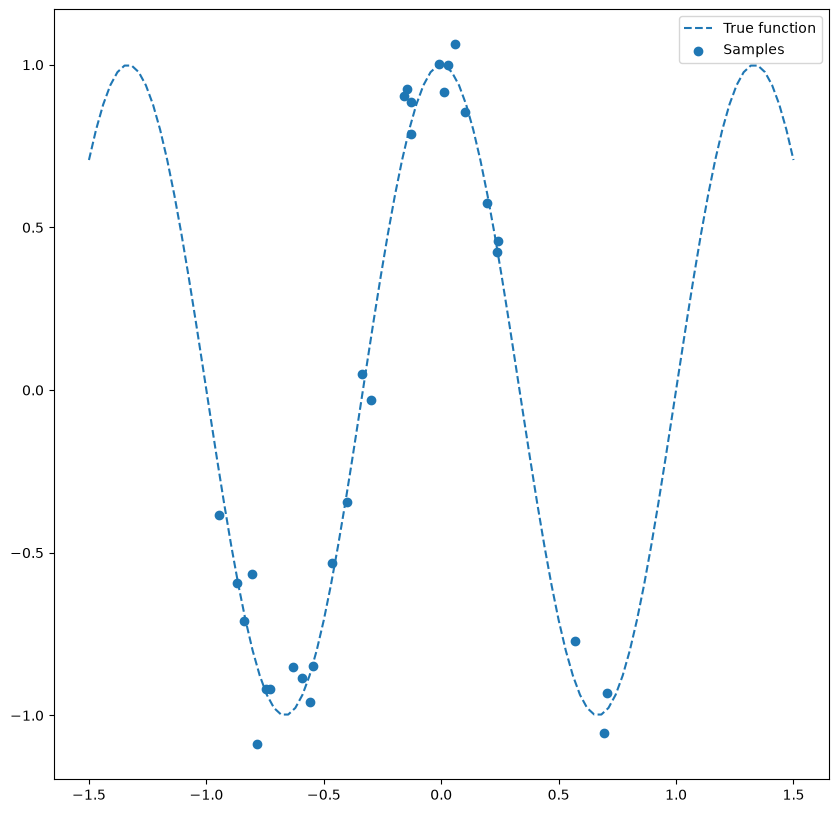

In [2]:
n_samples = 30

# True Function we want to estimate
def true_func(X): return np.cos(1.5 * np.pi * X)

# Noisy Samples from the true function
np.random.seed(SEED)
X = np.sort(2*np.random.rand(n_samples)-1)
y = true_func(X) + np.random.randn(n_samples) * 0.1

plt.figure(figsize=(10,10))
# Plot the true function:
X_plot = np.linspace(-1.5, 1.5, 100)
plt.plot(X_plot, true_func(X_plot), '--',label="True function")
# Plot the data samples
plt.scatter(X,y, label="Samples")
plt.legend(loc="best")
plt.show()

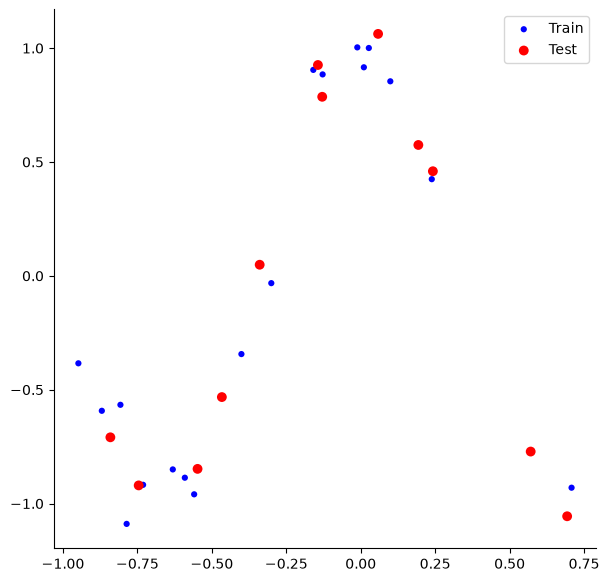

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.4, random_state=0)
plt.figure(figsize=(7,7))
# Plot the data samples
plt.scatter(X_train,y_train, label="Train", c='Blue', s=20, edgecolors='none')
plt.scatter(X_test,y_test, label="Test", c='Red', s=50, edgecolors='none')
#plt.plot(X_plot, true_func(X_plot), 'g--',label="True function")
plt.legend(loc="best")
sns.despine()
plt.show()

In [4]:
# Convert the data into a shape and data-type that PyTorch likes
X_train = X_train.reshape(-1,1).astype(np.float32)
y_train = y_train.reshape(-1,1).astype(np.float32)

### Linear Regression

In [5]:
#| code-fold: false
input_size  = 1
output_size = 1
# Linear regression model (seeded, so its random initial weights are the same every run)
torch.manual_seed(SEED)
model = nn.Linear(input_size, output_size)

# Loss and optimizer
criterion = nn.MSELoss()
learning_rate = 0.1 # alpha
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)


In [6]:
#| code-fold: false
# Train the model
num_epochs = 100
for epoch in range(num_epochs):
    # Convert numpy arrays to torch tensors
    inputs = torch.from_numpy(X_train)
    targets = torch.from_numpy(y_train)

    # Forward pass
    outputs = model(inputs)
    loss = criterion(outputs, targets)
    
    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if (epoch+1) % 20 == 0:
        print ('Epoch [{}/{}], Loss: {:.4f}'.format(epoch+1, num_epochs, loss.item()))

Epoch [20/100], Loss: 0.4881
Epoch [40/100], Loss: 0.4625
Epoch [60/100], Loss: 0.4562
Epoch [80/100], Loss: 0.4547
Epoch [100/100], Loss: 0.4543


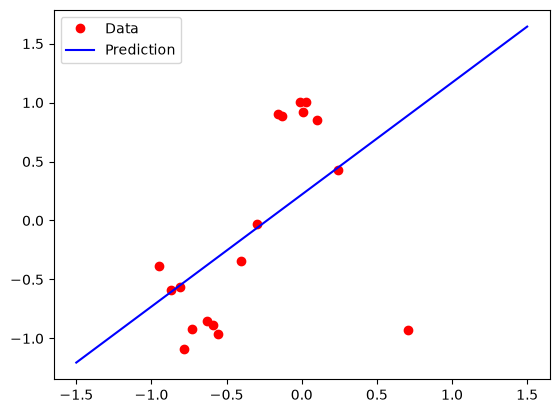

In [7]:
# Plot the graph
plt.figure()
plt.plot(X_train, y_train, 'ro', label='Data')
#predicted = model(torch.from_numpy(X_train)).detach().numpy()
#plt.plot(X_train, predicted, 'b+',label='Predictions')
predicted = model(torch.from_numpy(X_plot.reshape(-1,1).astype(np.float32))).detach().numpy()
plt.plot(X_plot, predicted, 'b', label='Prediction')
plt.legend()
plt.show()

### Neural Network Examples

#### Example of Defining a Network via the full Module class

In [8]:
#| code-fold: false
class Net(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(Net, self).__init__()  
        # Fully-Connected Layer: 1 (input data) -> 5 (hidden node)
        self.fc1 = nn.Linear(input_size, hidden_size)  
        
        # Non-Linear Layer
        self.sigmoid = nn.Sigmoid()
        # You can try other kinds as well
        # self.relu = nn.ReLU()
        # self.elu = nn.ELU()
        
        
        # Fully-Connected Layer: 5 (hidden node) -> 1 (output)
        self.fc2 = nn.Linear(hidden_size, 1) 
    
    # Forward pass builds the model prediction from the inputs
    def forward(self, x):                              
        out = self.fc1(x)
        out = self.sigmoid(out)
        out = self.fc2(out)
        return out
    
# Build the network -- is it not trained yet
model = Net(input_size=1, hidden_size=5)

#### Example of building a model using the `Sequential` helper function

In [9]:
input_size=1
hidden_size=4
model = nn.Sequential(
          nn.Linear(input_size, hidden_size),
          nn.Sigmoid(),
          nn.Linear(hidden_size, hidden_size),
          nn.ReLU(),
          nn.Linear(hidden_size, 1)
        )

#### Example using Python list expansions to help build deeper networks

In [10]:
input_size=1
hidden_size=7
num_hidden_layers = 3
activation = nn.ReLU

# Seed so that this network starts from the same random weights every run
torch.manual_seed(SEED)
input_layer = [nn.Linear(input_size, hidden_size),
                activation()]
# Build a fresh Linear layer in every pass of the loop. (Writing
# num_hidden_layers*[nn.Linear(hidden_size, hidden_size), activation()] would repeat
# the *same* layer object, so all hidden layers would share one set of weights.)
hidden_layers = []
for _ in range(num_hidden_layers):
    hidden_layers.append(nn.Linear(hidden_size, hidden_size))
    hidden_layers.append(activation())
    # hidden_layers.append(nn.Dropout(p=0.1))  # dropout, see "Regularizing the Network" below;
    # if you use it, call model.eval() before plotting the prediction
output_layer = [ nn.Linear(hidden_size, 1) ] 

# Stack them all together
layers = input_layer + hidden_layers + output_layer

print(layers)

# Use the * operator to "expand" or "unpack" the list
model = nn.Sequential(*layers)

[Linear(in_features=1, out_features=7, bias=True), ReLU(), Linear(in_features=7, out_features=7, bias=True), ReLU(), Linear(in_features=7, out_features=7, bias=True), ReLU(), Linear(in_features=7, out_features=7, bias=True), ReLU(), Linear(in_features=7, out_features=1, bias=True)]


### Now let's do the actual training

In [11]:
#| code-fold: false
# What Loss function should we use? MSE!
criterion = nn.MSELoss()

# What Optimization procedure should we use?

##### Change these and let's see how it affects the model fit #################
learning_rate = 0.05
weight_decay = 0.0
##########################
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

In [12]:
#| code-fold: false
### Train the model

# Convert numpy arrays to torch tensors
inputs = torch.from_numpy(X_train)
targets = torch.from_numpy(y_train)

num_epochs = 5000
for epoch in range(num_epochs):

    ## Do Forward pass
    # Make predictions
    outputs = model(inputs)
    # Compute the loss function
    loss = criterion(outputs, targets)
    
    ## Update the model
    # Reset the optimizer gradients
    optimizer.zero_grad()
    # Compute the gradient of the loss function
    loss.backward()
    # Do an optimization step
    optimizer.step()
    
    # Print the loss
    if (epoch+1) % 200 == 0:
        print ('Epoch [{:4}/{}], Loss: {:.4f}'.format(epoch+1, num_epochs, loss.item()))

Epoch [ 200/5000], Loss: 0.0131
Epoch [ 400/5000], Loss: 0.0131
Epoch [ 600/5000], Loss: 0.0132
Epoch [ 800/5000], Loss: 0.0136
Epoch [1000/5000], Loss: 0.0119
Epoch [1200/5000], Loss: 0.0159
Epoch [1400/5000], Loss: 0.0095
Epoch [1600/5000], Loss: 0.0093
Epoch [1800/5000], Loss: 0.0090
Epoch [2000/5000], Loss: 0.0086
Epoch [2200/5000], Loss: 0.0088
Epoch [2400/5000], Loss: 0.0088
Epoch [2600/5000], Loss: 0.0084
Epoch [2800/5000], Loss: 0.0085
Epoch [3000/5000], Loss: 0.0073
Epoch [3200/5000], Loss: 0.0070
Epoch [3400/5000], Loss: 0.0069
Epoch [3600/5000], Loss: 0.0069
Epoch [3800/5000], Loss: 0.0069
Epoch [4000/5000], Loss: 0.0069
Epoch [4200/5000], Loss: 0.0069
Epoch [4400/5000], Loss: 0.0069
Epoch [4600/5000], Loss: 0.0069
Epoch [4800/5000], Loss: 0.0068
Epoch [5000/5000], Loss: 0.0058


Now let's plot the prediction:

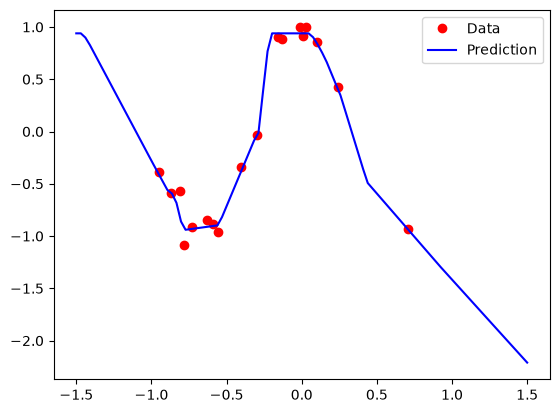

In [13]:
# Plot the graph
plt.figure()
plt.plot(X_train, y_train, 'ro', label='Data')
predicted = model(torch.from_numpy(X_plot.reshape(-1,1).astype(np.float32))).detach().numpy()
plt.plot(X_plot, predicted, 'b', label='Prediction')
plt.legend()
plt.show()

::: {.callout-tip appearance="default"}
### Experiment: Effect of Regularization on Simple Toy Regression Problem
Revisit the above regression code and experiment with the weight decay parameter in the Adam optimizer. How does this affect the learned function? Why do you think this is? The section *Regularizing the Network* below shows what this penalty does to the weights.

:::

You can also play around with different activation functions, e.g., `nn.ReLU()`, `nn.Sigmoid()`, `nn.Tanh()`, etc., and the below plot pulls out several options from PyTorch for you to visualize the activation functions:

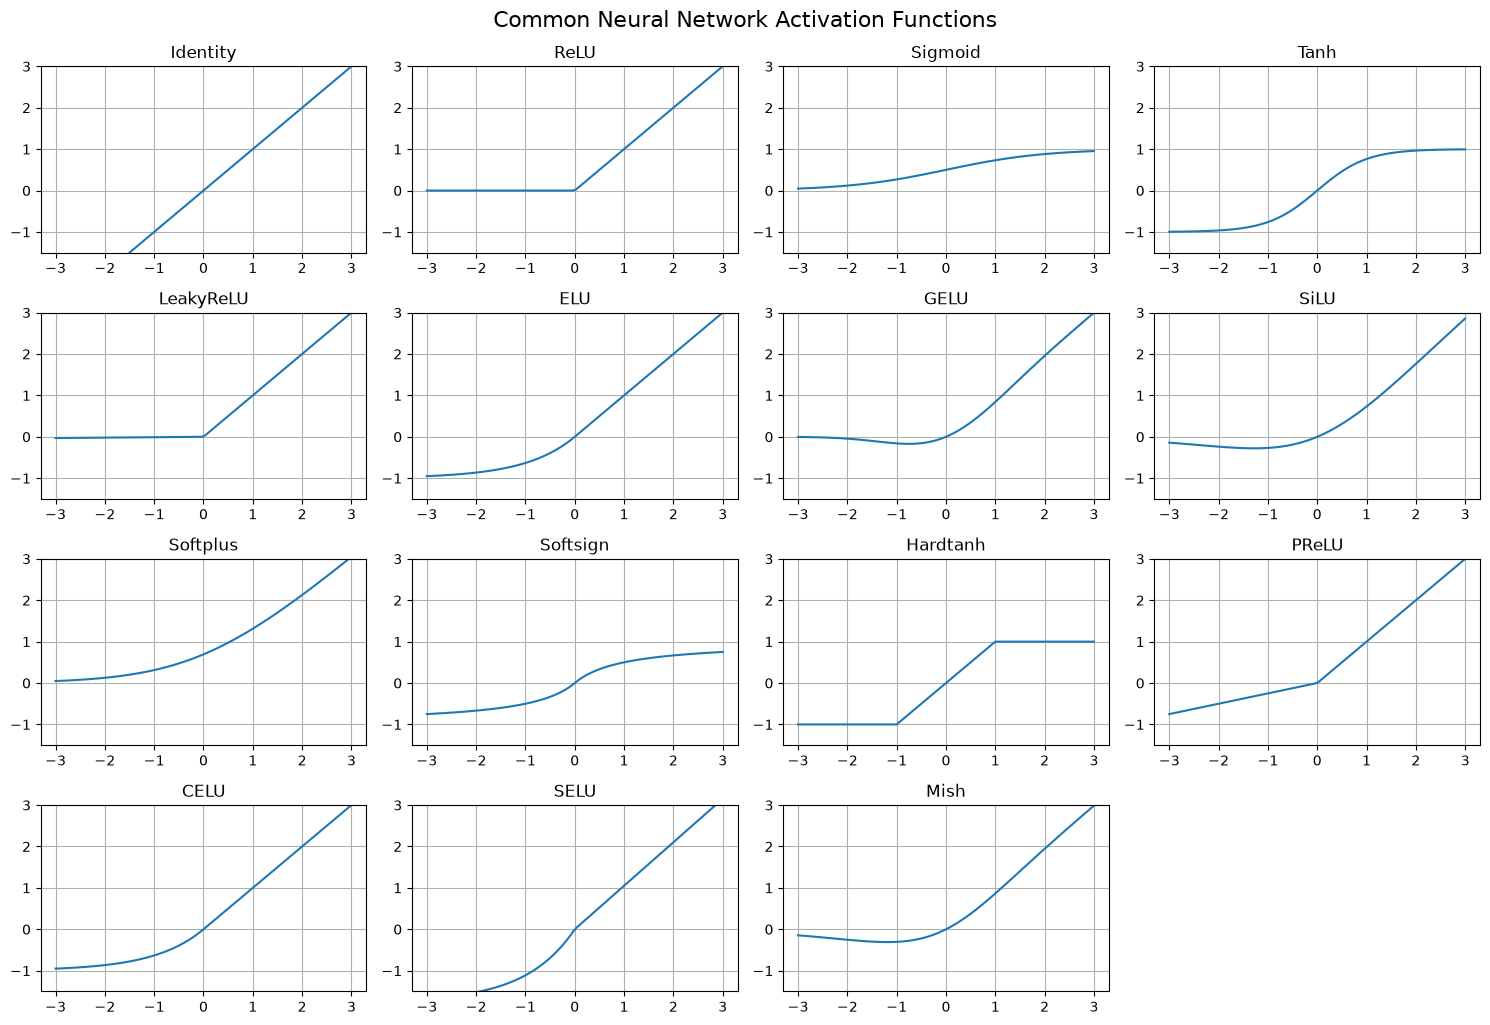

In [14]:
# Common activation functions from PyTorch:
activations = {
    'Identity': nn.Identity(),
    'ReLU': nn.ReLU(),
    'Sigmoid': nn.Sigmoid(),
    'Tanh': nn.Tanh(),
    'LeakyReLU': nn.LeakyReLU(),
    'ELU': nn.ELU(),
    'GELU': nn.GELU(),
    'SiLU': nn.SiLU(),  # also known as Swish
    'Softplus': nn.Softplus(),
    'Softsign': nn.Softsign(),
    'Hardtanh': nn.Hardtanh(),
    'PReLU': nn.PReLU(),
    'CELU': nn.CELU(),
    'SELU': nn.SELU(),
    'Mish': nn.Mish()
}
x = torch.linspace(-3, 3, 100)
n = len(activations)
ncols = 4
nrows = int(np.ceil(n/ncols))
plt.figure(figsize=(15,10))
for i, (name, activation) in enumerate(activations.items()):
    plt.subplot(nrows, ncols, i+1)
    plt.plot(x.numpy(), activation(x).detach().numpy())
    plt.ylim([-1.5, 3])
    plt.title(name)
    plt.grid()
plt.tight_layout()
plt.suptitle("Common Neural Network Activation Functions", y=1.02, fontsize=16)
plt.show()


### Regularizing the Network

The network above has 190 parameters and only 18 training points, so many different weight settings fit the data equally well. As we saw in the Linear Models chapters, regularization refers to changes we make to the training procedure to penalize the complexity of the model (network in this case). We'll explore common ways to do this below, but first, to make the network overfitting easy to see, the cells below use a wider network (two hidden layers of 64 Tanh units, about 4,000 weights) that overfits our data, and then reports the error on the 12 held-out points from before.

In [15]:
# The held-out points
X_test_t = torch.from_numpy(X_test.reshape(-1, 1).astype(np.float32))
y_test_t = torch.from_numpy(y_test.reshape(-1, 1).astype(np.float32))
x_grid = torch.linspace(-1.5, 1.5, 301).reshape(-1, 1)


def make_wide_net(dropout=0.0, width=64, seed=SEED):
    """Two hidden layers of `width` Tanh units, with optional dropout after each one."""
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(1, width), nn.Tanh(), nn.Dropout(dropout),
        nn.Linear(width, width), nn.Tanh(), nn.Dropout(dropout),
        nn.Linear(width, 1),
    )


def weight_penalty(net, kind):
    """Sum of squared (L2) or absolute (L1) weights. Biases are not penalized."""
    weights = [p for name, p in net.named_parameters() if name.endswith("weight")]
    if kind == "L2":
        return sum((w**2).sum() for w in weights)
    if kind == "L1":
        return sum(w.abs().sum() for w in weights)
    return 0.0


def train_net(net, penalty=None, lam=0.0, epochs=5000, learning_rate=0.01):
    """The training loop from above (with learning rate 0.01, which suits the wider network), plus an optional weight penalty.

    Records the training and held-out MSE after every epoch, and keeps a copy of the
    weights from the epoch with the lowest held-out MSE.
    """
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    inputs, targets = torch.from_numpy(X_train), torch.from_numpy(y_train)
    history = {"train": [], "test": [], "best_state": None}
    for epoch in range(epochs):
        net.train()
        loss = F.mse_loss(net(inputs), targets) + lam * weight_penalty(net, penalty)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        net.eval()
        with torch.no_grad():
            history["train"].append(F.mse_loss(net(inputs), targets).item())
            history["test"].append(F.mse_loss(net(X_test_t), y_test_t).item())
        if history["test"][-1] == min(history["test"]):
            history["best_state"] = {k: v.clone() for k, v in net.state_dict().items()}
    return history


def plot_fit(ax, net, title):
    """True function, training and held-out points, and the network's prediction."""
    net.eval()
    with torch.no_grad():
        prediction = net(x_grid).numpy()
    ax.plot(x_grid, true_func(x_grid.numpy()), "k--", lw=1, label="true function")
    ax.plot(x_grid, prediction, "tab:blue", lw=2, label="prediction")
    ax.scatter(X_train, y_train, c="tab:red", s=15, zorder=3, label="train")
    ax.scatter(X_test, y_test, c="tab:green", marker="x", s=25, zorder=3, label="held out")
    ax.set_ylim(-3, 2)
    ax.set_xlabel("x")
    ax.set_title(title, fontsize=10)

#### Weight Penalties (L2 and L1)

As with Linear Models, we can add a penalty $\Omega$ on the weights to the loss,

$$
\mathcal{L}(\theta) = \frac{1}{N}\sum_{i=1}^{N} \left(y_i - f_W(x_i)\right)^2 + \lambda\, \Omega(W),
\qquad
\Omega_{L2} = \sum_{\ell} \|W_\ell\|_F^2 = \sum w^2,
\qquad
\Omega_{L1} = \sum_{w \in W} |w| .
$$

These are the ridge and lasso penalties from the chapter *Reviewing Supervised Linear Models*, applied to every weight matrix $W_\ell$ of the network. The `weight_decay` argument of the optimizer above adds the gradient of the L2 penalty for you (with `weight_decay` $= 2\lambda$, and it also shrinks the biases). `torch.optim.AdamW`, used for the autoencoder below, instead shrinks the weights directly at every step, so the shrinkage is not rescaled by Adam's per-weight step sizes.

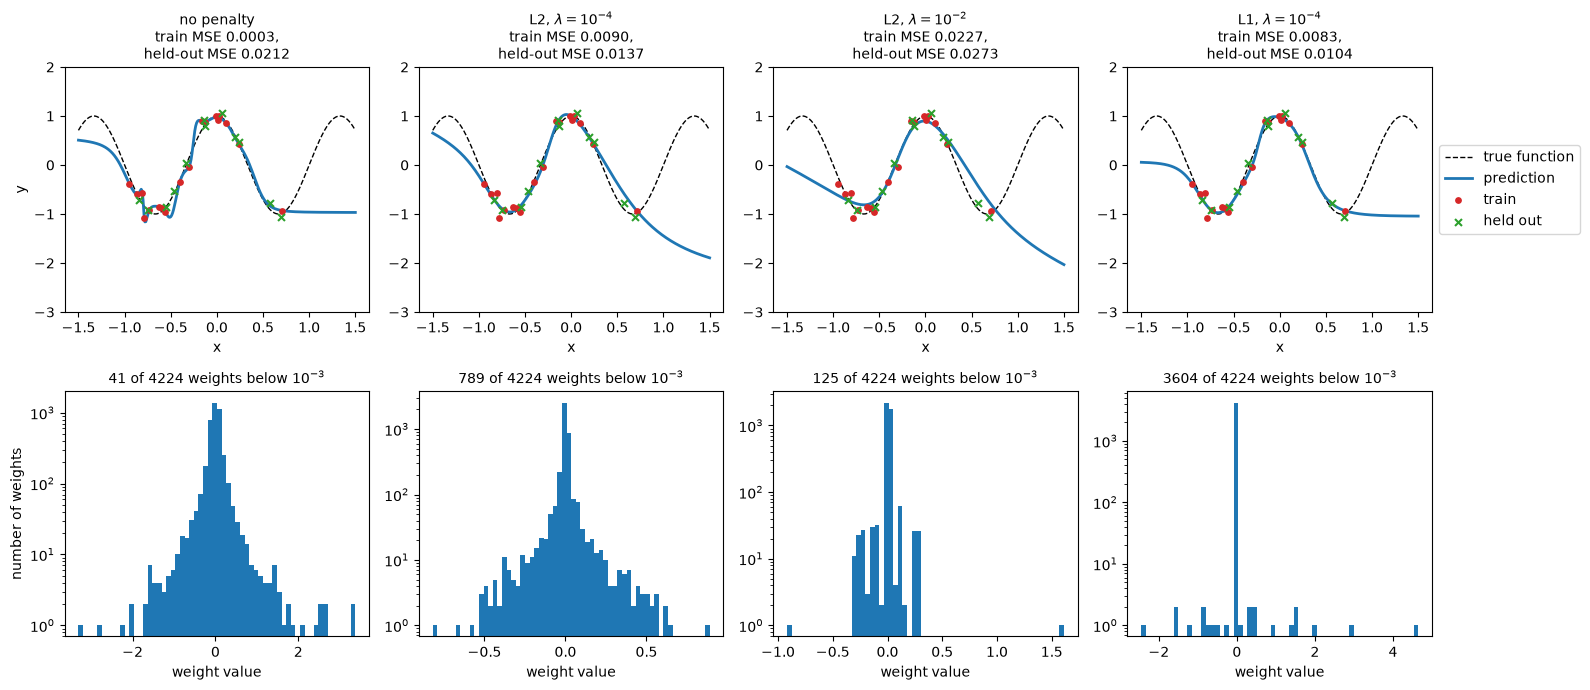

In [16]:
penalty_runs = {
    "no penalty": (None, 0.0),
    "L2, $\\lambda = 10^{-4}$": ("L2", 1e-4),
    "L2, $\\lambda = 10^{-2}$": ("L2", 1e-2),
    "L1, $\\lambda = 10^{-4}$": ("L1", 1e-4),
}
wide_nets, histories = {}, {}
fig, axes = plt.subplots(2, len(penalty_runs), figsize=(16, 7))
for col, (label, (penalty, lam)) in enumerate(penalty_runs.items()):
    net = make_wide_net()
    histories[label] = train_net(net, penalty, lam)
    wide_nets[label] = net
    plot_fit(axes[0, col], net, f"{label}\ntrain MSE {histories[label]['train'][-1]:.4f},\n"
                                f"held-out MSE {histories[label]['test'][-1]:.4f}")

    weights = torch.cat([p.detach().ravel() for name, p in net.named_parameters() if name.endswith("weight")])
    axes[1, col].hist(weights.numpy(), bins=60)
    axes[1, col].set_yscale("log")
    axes[1, col].set_xlabel("weight value")
    axes[1, col].set_title(f"{int((weights.abs() < 1e-3).sum())} of {weights.numel()} weights below $10^{{-3}}$",
                           fontsize=10)
axes[0, 0].set_ylabel("y")
axes[1, 0].set_ylabel("number of weights")
axes[0, -1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

If you look at the bottom row, we see that the L2 shrinks all weights toward zero, and a large $\lambda$ shrinks them so much that the fit becomes too stiff to follow the data closely. L1 pushes most weights to (almost exactly) zero and leaves a few large ones.

#### Early Stopping

Instead of changing the loss, we can also just stop training early. We can watch the error on held-out data and then only keep the weights from the epoch $t^\ast$ where it was lowest (this is sometimes referred to as "checkpointing" the model on the lowest validation error),

$$
t^\ast = \arg\min_{t} \; \mathcal{L}_{\text{held out}}(\theta_t).
$$

`train_net` already recorded both errors and kept the best weights, so we only need to plot the unpenalized run from above.

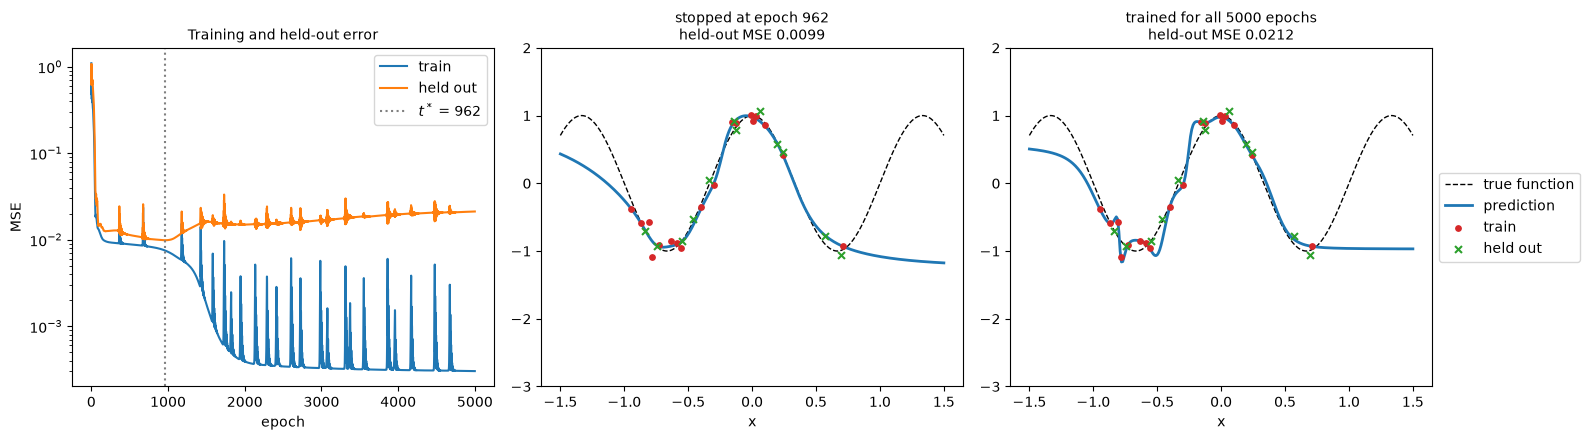

In [17]:
history = histories["no penalty"]
best_epoch = int(np.argmin(history["test"]))
early_net = make_wide_net()
early_net.load_state_dict(history["best_state"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].semilogy(history["train"], label="train")
axes[0].semilogy(history["test"], label="held out")
axes[0].axvline(best_epoch, color="gray", ls=":", label=f"$t^*$ = {best_epoch}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("Training and held-out error", fontsize=10)
axes[0].legend()
plot_fit(axes[1], early_net, f"stopped at epoch {best_epoch}\nheld-out MSE {history['test'][best_epoch]:.4f}")
plot_fit(axes[2], wide_nets["no penalty"], f"trained for all {len(history['test'])} epochs\n"
                                            f"held-out MSE {history['test'][-1]:.4f}")
axes[2].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

#### Dropout

Dropout randomly switches off hidden units during training. In each forward pass, every hidden activation $h_j$ is replaced by

$$
\tilde{h}_j = \frac{m_j\, h_j}{1-p}, \qquad m_j \sim \text{Bernoulli}(1-p),
$$

so each unit is dropped with probability $p$, and the factor $1/(1-p)$ keeps the average signal the same. No unit can rely on any particular activation or neuron being present, and thus, the logic goes, it is less likely to overfit. In PyTorch, `nn.Dropout(p)` is a layer, `net.train()` turns the random masks on and `net.eval()` turns them off. Below, the gray curves are 30 predictions with random masks (training mode) and the blue curve is the prediction in evaluation mode. (You can re-run the below cell with different `dropout_rates` if you wish to explore this effect further -- what do you think happens if you push it up to, say, 0.9?)

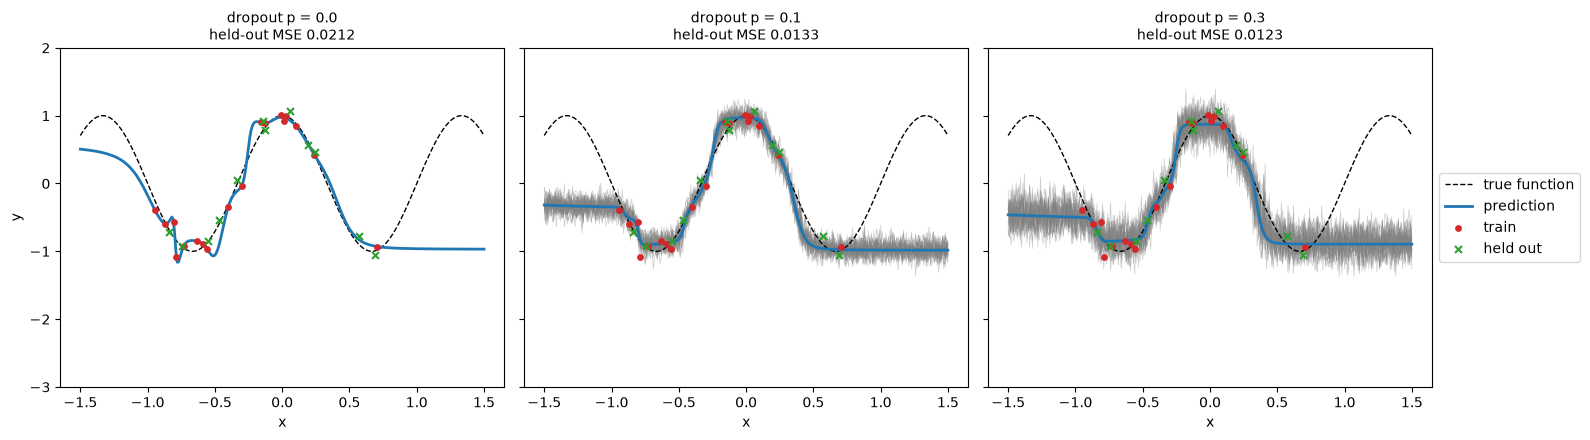

In [18]:
dropout_rates = [0.0, 0.1, 0.3]
fig, axes = plt.subplots(1, len(dropout_rates), figsize=(16, 4.5), sharey=True)
for ax, p in zip(axes, dropout_rates):
    net = make_wide_net(dropout=p)
    history = train_net(net)
    net.train()  # dropout masks on
    torch.manual_seed(SEED)
    with torch.no_grad():
        for _ in range(30):
            ax.plot(x_grid, net(x_grid).numpy(), color="gray", lw=0.5, alpha=0.4)
    plot_fit(ax, net, f"dropout p = {p}\nheld-out MSE {history['test'][-1]:.4f}")  # plot_fit calls net.eval()
axes[0].set_ylabel("y")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

::: {.callout-tip appearance="default"}
### Experiment: Combining Regularizers
Change $\lambda$, the penalty type, the dropout rate $p$, and the network width in the cells above.

- Which value of $\lambda$ gives the lowest held-out error for L2, and which for L1? Why is the held-out error a noisy guide with only 12 points?
- Does early stopping still help when you add a weight penalty or dropout? Why?
- Where is the spread of the gray dropout curves largest? Should you read it as an uncertainty estimate? Why or why not?
:::

## Unsupervised Learning using Autoencoders

For this demonstration, we will construct what is fundamentally a 1D function (t) but then embed it in a higher-dimensional space (3D) using a non-linear transformation. This will allow us to compare what a linear method (PCA) can do versus a non-linear method (Autoencoder), on a simple example.

In [19]:
#| code-fold: false
# First we create a simple line (t)
t = np.linspace(-1,1,100)

In [20]:
#| code-fold: false
# Now let's make it 3D and add some (optional) noise
noise_level = 0.01
# You can try out different functions below by uncommenting/commenting them
#X = np.vstack([t,1*t**2,-1*t**3, 0.4*t**5,t**2-t**3,-0.4*t**4]).T
#X = np.vstack([2*np.sin(3*t),1*t**2,-1*t**3, 2*np.sin(6*t+1)-t**3,2*np.cos(3*t)]).T
np.random.seed(SEED)
X = np.vstack([np.sin(2*t),1*t**2,1*np.cos(5*t)]).T + noise_level*np.random.randn(len(t),3)

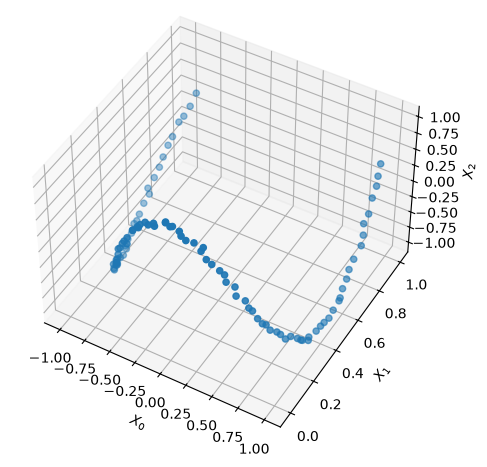

In [21]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X[:,0], X[:,1], X[:,2])
ax.set_xlabel('$X_0$')
ax.set_ylabel('$X_1$')
ax.set_zlabel('$X_2$')
ax.elev=45
plt.tight_layout()
plt.show()

We can see that it results in 100 points each of which has three dimensions:

In [22]:
#| code-fold: false
X.shape

(100, 3)

We can attempt to reduce the dimensionality of this data using PCA, but as we can already see from the 3D plot, the data is not linearly embedded in 3D space, so PCA will not be able to find a good low-dimensional representation:

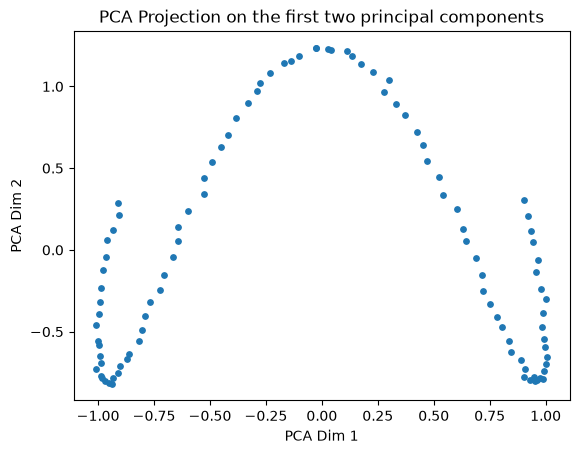

In [23]:
#| code-fold: false
pca = PCA(3)
Z_PCA =pca.fit_transform(X)
plt.figure()
plt.scatter(Z_PCA[:,0],Z_PCA[:,1],s=15)
plt.xlabel('PCA Dim 1')
plt.ylabel('PCA Dim 2')
plt.title('PCA Projection on the first two principal components')
plt.show()

And we can also see this reflected in the explained variance, which shows that we need all three original dimensions to explain the variance in the data, even though we know that the data fundamentally lies on a 1D manifold:

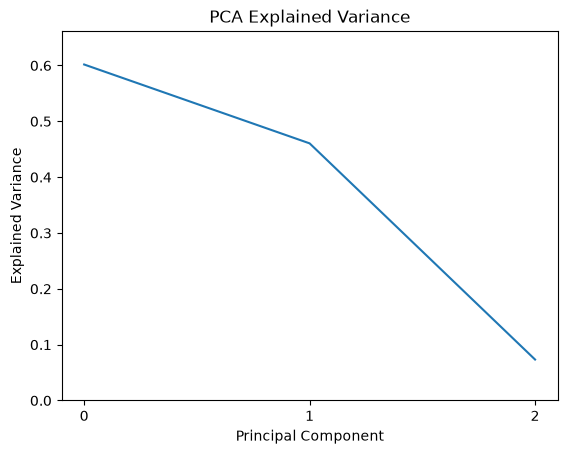

In [24]:
plt.figure()
plt.plot(pca.explained_variance_)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance')
plt.title('PCA Explained Variance')
plt.xticks([0,1,2])
plt.ylim(0,1.1*max(pca.explained_variance_))
plt.show()

We can see below what happens if we try to truncate PCA to only two dimensions and then reconstruct back to 3D space. The reconstruction is not very good, as expected, and what do you notice about the shape of the reconstructed data?

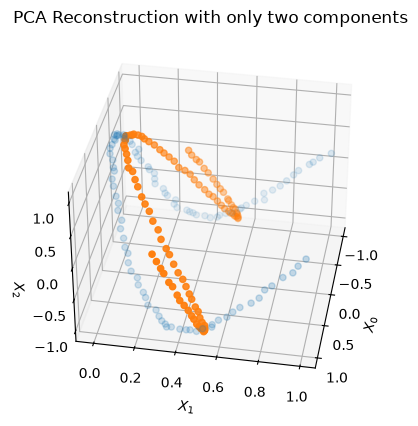

In [25]:

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
pca_2d = PCA(2)
Z_PCA = pca_2d.fit_transform(X)
X_PCA= pca_2d.inverse_transform(Z_PCA)
ax.scatter(X[:,0], X[:,1], X[:,2],alpha=0.5)
ax.scatter(X_PCA[:,0], X_PCA[:,1], X_PCA[:,2])

ax.set_xlabel('$X_0$')
ax.set_ylabel('$X_1$')
ax.set_zlabel('$X_2$')
ax.elev=35
ax.azim=10
plt.title("PCA Reconstruction with only two components")
plt.show()

Now let's see how this works using an autoencoder. We will use a very simple architecture with just one hidden layer in the encoder and one hidden layer in the decoder, and we will start with a three-dimensional latent space, even though we know that the data is fundamentally 1D (the experiment below asks you to try a 1D latent space and see why that is harder than it sounds). You will have the option in the below code to change the number of hidden units in the encoder and decoder, as well as the number of latent dimensions, and see how this affects the results.

In [26]:
#| code-fold: false
class Encoder(nn.Module):
    def __init__(self, num_input, num_latent,num_hidden):
        super().__init__()
        self.num_input  = num_input
        self.num_latent = num_latent
        self.num_hidden = num_hidden
        
        # I encourage you to modify the architecture here by adding more layers or changing activation functions, if you wish
        self.encode = nn.Sequential(
            nn.Linear(self.num_input, self.num_hidden),
            nn.ReLU(),
            #nn.Linear(self.num_hidden, self.num_hidden),
            #nn.ReLU(),
            nn.Linear(self.num_hidden, self.num_latent),
        )
        
    def forward(self, X):
        encoded = self.encode(X)
        return encoded
    
class Decoder(nn.Module):
    def __init__(self, num_input, num_latent,num_hidden):
        super().__init__()
        self.num_input  = num_input
        self.num_latent = num_latent
        self.num_hidden = num_hidden
        
        self.decode = nn.Sequential(
            nn.Linear(self.num_latent, self.num_hidden),
            nn.ReLU(),
            #nn.Linear(self.num_hidden, self.num_hidden),
            #nn.ReLU(),
            nn.Linear(self.num_hidden, self.num_input)
        )
        
    def forward(self, Z):
        decoded = self.decode(Z)
        return decoded
    
class AutoEncoder(nn.Module):
    def __init__(self, num_input,num_latent,num_hidden):
        super().__init__()
        self.num_input  = num_input
        self.num_latent = num_latent
        self.num_hidden = num_hidden
        
        self.encoder = Encoder(num_input  = self.num_input,
                               num_latent = self.num_latent,
                               num_hidden = self.num_hidden)
        self.decoder = Decoder(num_input  = self.num_input,
                               num_latent = self.num_latent,
                               num_hidden = self.num_hidden)
        
    def forward(self, X):
        encoded = self.encoder(X)
        decoded = self.decoder(encoded)
        return decoded, encoded  # <- return a tuple of two values
    
    def transform(self,X):
        '''Take X and encode to latent space'''
        return self.encoder(X)
    
    def inverse_transform(self,Z):
        '''Take Z and decode to X space'''
        return self.decoder(Z)

In [27]:
#| code-fold: false
# Here we can set some parameters for the autoencoder that we are about to train
# What happens if you change them?
# e.g., increase/decrease num_latent, num_hidden, learning rate, weight decay
num_points, D_orig = X.shape
num_latent = 1
num_hidden = 5
# Unlike the rest of this notebook, we deliberately do not reseed here: each time you
# re-run this cell (and the training cell below), the network starts from new random
# weights, so you can see how much the result varies from run to run.
model = AutoEncoder(D_orig,num_latent,num_hidden)
# Create the optimizer object:
# AdamW optimizer (Adam with decoupled weight decay) with learning rate and weight decay
# I encourage you to try out different learning rates and weight decays and
# observe their effect on the model
optimizer = optim.AdamW(model.parameters(), 
                        lr=1e-3, 
                        weight_decay=1e-2)
# Add a mean-squared error loss
criterion = nn.MSELoss()

In [28]:
#| code-fold: false
X_torch = torch.from_numpy(X)
X_torch = X_torch.float()

# Depending on the model architecture you use, you may need to increase or decrease this to get good training
epochs=10000
for epoch in range(epochs):
    loss = 0

    optimizer.zero_grad()

    # compute reconstructions
    decoded, encoded = model(X_torch)

    # compute training reconstruction loss
    train_loss = criterion(decoded, X_torch)
            
    # Total Loss
    loss = train_loss 
    
    # compute accumulated gradients
    loss.backward()

    # perform parameter update based on current gradients
    optimizer.step()

    # display the epoch training loss
    if epoch%500==0:
        print("epoch : {}/{}, loss = {:.6f}".format(epoch + 1, epochs, loss.item()))

epoch : 1/10000, loss = 0.786044
epoch : 501/10000, loss = 0.243566
epoch : 1001/10000, loss = 0.221194
epoch : 1501/10000, loss = 0.219298
epoch : 2001/10000, loss = 0.199980
epoch : 2501/10000, loss = 0.054346
epoch : 3001/10000, loss = 0.040893
epoch : 3501/10000, loss = 0.034647
epoch : 4001/10000, loss = 0.033092
epoch : 4501/10000, loss = 0.032670
epoch : 5001/10000, loss = 0.032516
epoch : 5501/10000, loss = 0.032462
epoch : 6001/10000, loss = 0.032403
epoch : 6501/10000, loss = 0.032337
epoch : 7001/10000, loss = 0.032263
epoch : 7501/10000, loss = 0.032189
epoch : 8001/10000, loss = 0.032121
epoch : 8501/10000, loss = 0.032061
epoch : 9001/10000, loss = 0.032003
epoch : 9501/10000, loss = 0.031962


Now that the model is trained, we can put the data through the encoder and decoder to pull out both the encoded (i.e., latent) representation of each point, as well as the decoded (i.e., reconstructed) version of each point, and visualize the results.

In [29]:
#|code-fold: false
decoded, encoded = model(X_torch)

First, let's take a look at the reconstructed data in the original 3D space, compared to the original data:

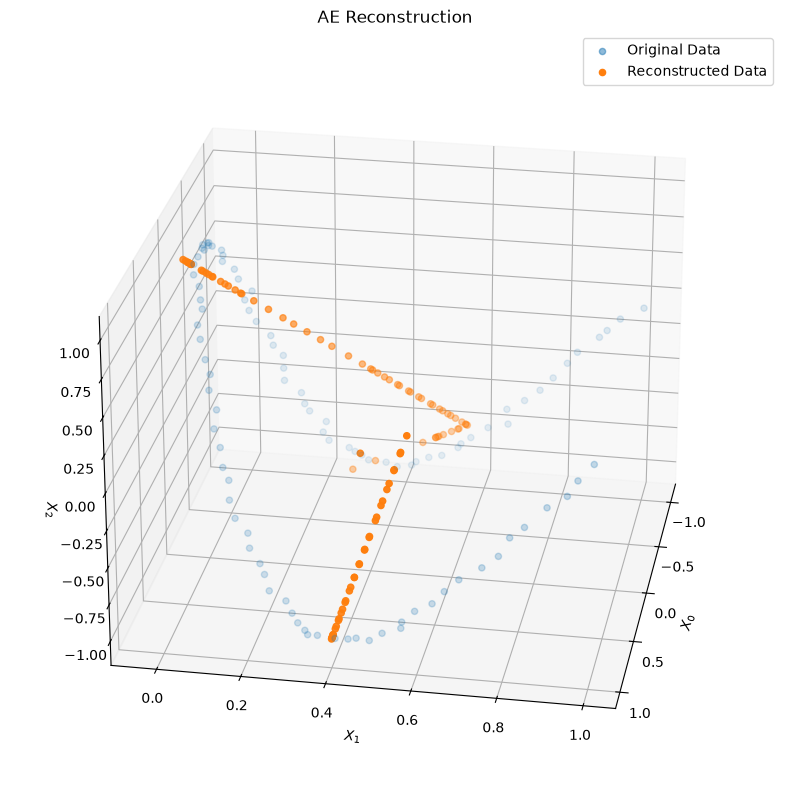

In [30]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(projection='3d')
X_P = decoded.detach().numpy()

ax.scatter(X[:,0], X[:,1], X[:,2],alpha=0.5)
ax.scatter(X_P[:,0], X_P[:,1], X_P[:,2])
ax.set_xlabel('$X_0$')
ax.set_ylabel('$X_1$')
ax.set_zlabel('$X_2$')
ax.elev=25
ax.azim=10
plt.legend(['Original Data','Reconstructed Data'])
plt.title("AE Reconstruction")
plt.show()

Let's see how the encoded (i.e., latent) points actually look in Z space:

In [31]:
Z = encoded.cpu().detach().numpy()
# Only works if num_latent >=2
if num_latent>=2:
    plt.figure()
    plt.scatter(Z[:,0],Z[:,1])
    plt.xlabel('z1')
    plt.ylabel('z2')
    plt.title('Latent Space Representation of the autoencoder')
    plt.show()

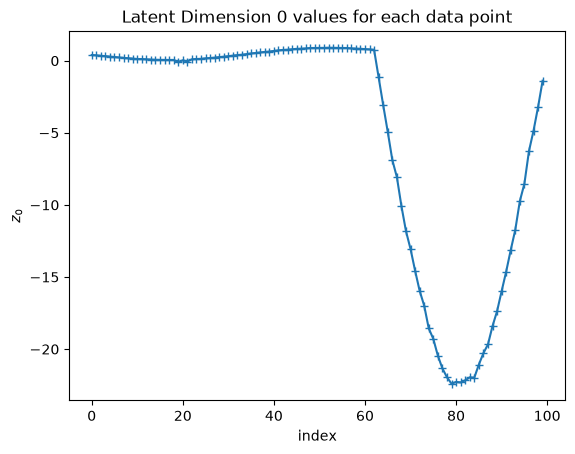

In [32]:
plt.figure()
plt.plot(Z[:,0],marker='+')
plt.xlabel('index')
plt.ylabel('$z_0$')
plt.title('Latent Dimension 0 values for each data point')
plt.show()

We can also look at a pairplot of the points in the latent space to get a sense of how the different dimensions correlate with each other:

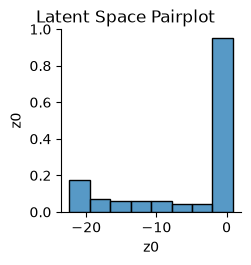

In [33]:
df = pd.DataFrame(Z, columns=[f'z{i}' for i in range(Z.shape[1])])
sns.pairplot(df)
plt.suptitle('Latent Space Pairplot', y=1.02)
plt.show()

::: {.callout-tip appearance="default"}
### Experiment: Effect of Autoencoder Architecture on Reconstruction Accuracy and Latent Space Behavior 
Revisit the above autoencoder code and experiment by changing the number of hidden units, the bottleneck (latent) dimension, and the number of layers in the encoder and decoder. How do these changes affect the reconstruction accuracy and the behavior of the learned latent space? Consider some of the below questions:

- We know that the data is fundamentally 1D, but why does setting the autoencoder latent dimension to 1 not work well? Why might it be useful to have a latent dimension larger than the true dimensionality of the data for this type of model?
- What happens if you set the latent dimension to be three or larger? Why do you think this happens? What have we given up by doing this?
- As you increase or decrease the number of hidden units in Autoencoder, how does this affect the reconstruction accuracy? Why do you think this is? Consider in particular the case where the number of hidden units is one or two.
- Unlike in PCA, when we re-run the autoencoder training, we get different results each time. Why do you think this is? (The cell that creates the autoencoder is deliberately not seeded, so re-running it and the training cell gives a new random start each time.)
- Unlike PCA, the autoencoder does not guarantee that the latent dimensions are orthogonal or ordered by importance (e.g., $z_0$ being more important than $z_1$, etc.). Do you see any evidence of this in the learned latent space? Why do you think this is?
- The Autoencoder used a ReLU activation function in the hidden layers. How does this manifest in the way that the network reconstructs the data? (Note, this may only be visible if you set the latent dimension to 1 and the number of hidden units to a small number, e.g., 2 or 3).
- We can see that when we set the latent dimension to two or greater, the autoencoder can reconstruct the data well, but it is not capturing the intrinsic dimensionality of the data. One way we might do this is by adding L1 regularization to the latent space coordinates. You will find this penalty commented out in the training loop of the deeper autoencoder in the next section. Try adding in this regularization, either there or in the training loop above (where the latent codes are called `encoded`). Does it fix the problem?

:::

## A Deeper Autoencoder, Before Least Volume Regularization

One of the problems that we saw in Autoencoders is that the latent space does not have any particular structure, and in particular, it is not guaranteed to be ordered, in the same sense as PCA. It was also difficult for us to determine the exact "size" of the latent dimension, since, as we saw, setting the latent dimension to 1 did not work well, even though we knew that the data was fundamentally 1D, due to training variability and the fact that the autoencoder could get trapped in local minima. One possible solution to this is to add a regularization term that encourages the latent space to be small in some sense. One such regularization is called [Least Volume Regularization](https://arxiv.org/abs/2404.17773), which encourages the latent space to have a small volume by penalizing the volume of the encoded points in the latent space. Before we add it, let's first train a deeper autoencoder without any regularization, so that we have something to compare against.

In [34]:
class _Combo(nn.Module):
    def forward(self, input):
        return self.model(input)

class LinearCombo(_Combo):
    def __init__(self, in_features, out_features, activation=nn.LeakyReLU(0.2)):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_features, out_features),
            activation
        )

class MLP(nn.Module):
    """Regular fully connected network generating features.

    Args:
        in_features: The number of input features.
        out_feature: The number of output features.
        layer_width: The widths of the hidden layers.
        combo: The layer combination to be stacked up.

    Shape:
        - Input: `(N, H_in)` where H_in = in_features.
        - Output: `(N, H_out)` where H_out = out_features.
    """
    def __init__(
        self, in_features: int, out_features:int, layer_width: list,
        combo = LinearCombo
        ):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.layer_width = list(layer_width)
        self.model = self._build_model(combo)

    def forward(self, input):
        return self.model(input)

    def _build_model(self, combo):
        model = nn.Sequential()
        idx = -1
        for idx, (in_ftr, out_ftr) in enumerate(self.layer_sizes[:-1]):
            model.add_module(str(idx), combo(in_ftr, out_ftr))
        model.add_module(str(idx+1), nn.Linear(*self.layer_sizes[-1])) # type:ignore
        return model

    @property
    def layer_sizes(self):
        return list(zip([self.in_features] + self.layer_width,
        self.layer_width + [self.out_features]))

In [35]:
#| code-fold: false
ambient_dim = X.shape[1]

# Change the below latent dimension to see what happens to the embedded points
latent_dim = 3

width = ambient_dim * 16
torch.manual_seed(SEED)
encoder = MLP(ambient_dim, latent_dim, [width] * 4)
decoder = MLP(latent_dim, ambient_dim, [width] * 4)

opt = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=1e-4)

In [36]:
#| code-fold: false
# Set X to a torch tensor:
X_torch = torch.from_numpy(X).float()

for i in range(5000):
    opt.zero_grad()
    z = encoder(X_torch)
    rec_loss = F.mse_loss(decoder(z), X_torch)
    loss = rec_loss
    # If you want, you can even add an L1 penalty on the latent space
    # to try to encourage sparsity by uncommenting the line below:
    #loss += 1e-3 * torch.mean(torch.abs(z))

    loss.backward()
    opt.step()
    if (i+1) % 100 == 0:
        print(f'Epoch {i:4}: rec = {rec_loss:.5g}')

Epoch   99: rec = 0.40929
Epoch  199: rec = 0.23014
Epoch  299: rec = 0.17192
Epoch  399: rec = 0.08683
Epoch  499: rec = 0.024894
Epoch  599: rec = 0.020454
Epoch  699: rec = 0.01756
Epoch  799: rec = 0.014212
Epoch  899: rec = 0.010387
Epoch  999: rec = 0.0063558
Epoch 1099: rec = 0.0026084
Epoch 1199: rec = 0.00080792
Epoch 1299: rec = 0.00029069
Epoch 1399: rec = 0.00013794
Epoch 1499: rec = 8.568e-05
Epoch 1599: rec = 6.6051e-05
Epoch 1699: rec = 5.6111e-05
Epoch 1799: rec = 4.9817e-05
Epoch 1899: rec = 4.5558e-05
Epoch 1999: rec = 4.2186e-05
Epoch 2099: rec = 3.9551e-05
Epoch 2199: rec = 3.7508e-05
Epoch 2299: rec = 3.5774e-05
Epoch 2399: rec = 3.4289e-05
Epoch 2499: rec = 3.2967e-05
Epoch 2599: rec = 3.1778e-05
Epoch 2699: rec = 3.0707e-05
Epoch 2799: rec = 2.9727e-05
Epoch 2899: rec = 2.8708e-05
Epoch 2999: rec = 2.7818e-05
Epoch 3099: rec = 2.6984e-05
Epoch 3199: rec = 2.6262e-05
Epoch 3299: rec = 2.5617e-05
Epoch 3399: rec = 2.5047e-05
Epoch 3499: rec = 2.4514e-05
Epoch 3599:

Now that the autoencoder has been trained, let's take a look at the standard deviation of the embedded points (i.e., in $z$). We can sort the latent dimensions according to which dimensions have the highest standard deviation in Z.

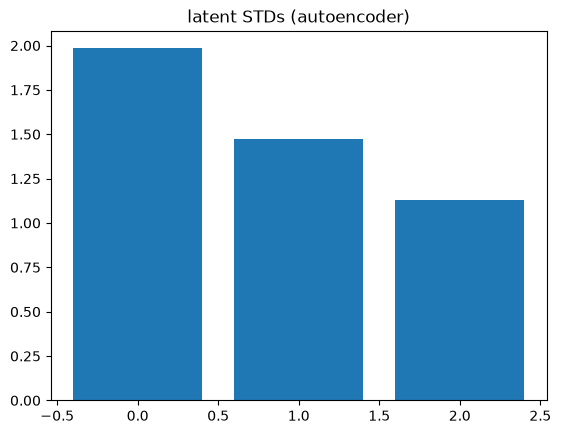

In [37]:
encoder.eval()
decoder.eval()

# Embed the data into Z using the trained encoder
with torch.no_grad():
    z = encoder(X_torch)
# Now let's sort the latent codes by which ones have the
# largest standard deviation in Z:
idx = z.std(0).argsort(descending=True)

plt.figure()
plt.bar(np.arange(z.std(0).size(-1)), z.std(0)[idx])
plt.title('latent STDs (autoencoder)')
plt.show()

As with before, we can plot some of the data points in Z space:

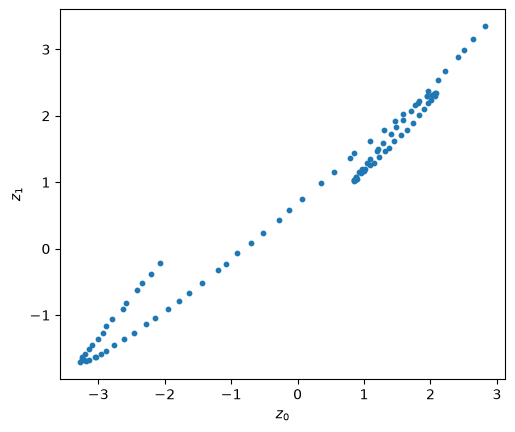

In [38]:
plt.figure()
plt.scatter(z[:, idx[0]].cpu().detach().numpy(), z[:, idx[1]].cpu().detach().numpy(), s=10)
plt.gca().set_aspect('equal')
plt.xlabel('$z_0$')
plt.ylabel('$z_1$')
plt.show()

We can also plot the covariance among the latent codes of the embedded data:

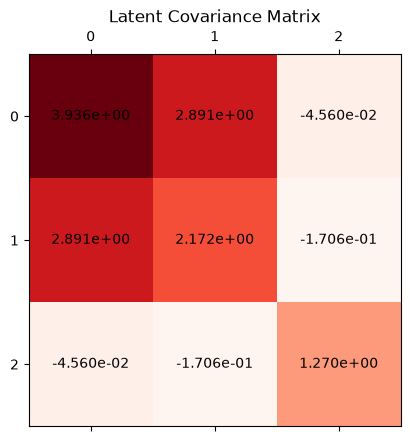

In [39]:
cov = z.T[idx].cov().detach().cpu().numpy()
plt.matshow(cov, cmap='Reds')
for (i, j), var in np.ndenumerate(cov):
    plt.gca().text(j, i, '{:.3e}'.format(var), ha='center', va='center')
plt.title('Latent Covariance Matrix')
plt.show()

We can also get a general idea about how well we are reconstructing the original data by comparing the ground truth values versus predicted (i.e., encoded then decoded) data points -- this is often called a parity plot:

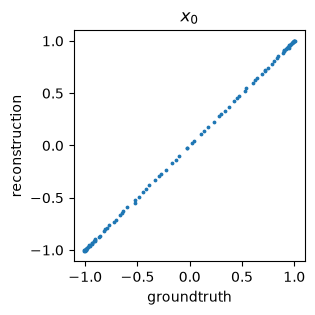

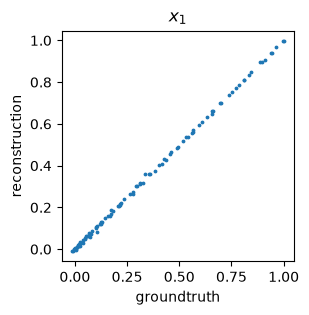

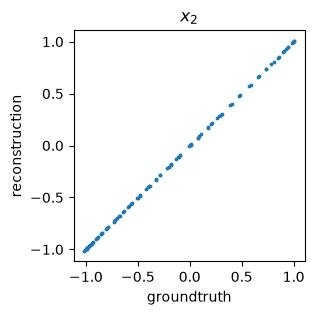

In [40]:
X_ = decoder(z).detach()

for i in range(X_torch.size(-1)):
    plt.figure(figsize=(3,3))
    plt.scatter(X[:, i], X_[:, i], s=3)
    plt.gca().set_aspect('equal')
    plt.xlabel('groundtruth')
    plt.ylabel('reconstruction')
    plt.title('$x_{}$'.format(i))
    plt.show()

Lastly, we can visualize a pairplot of the latent space to see how the different dimensions correlate with each other:

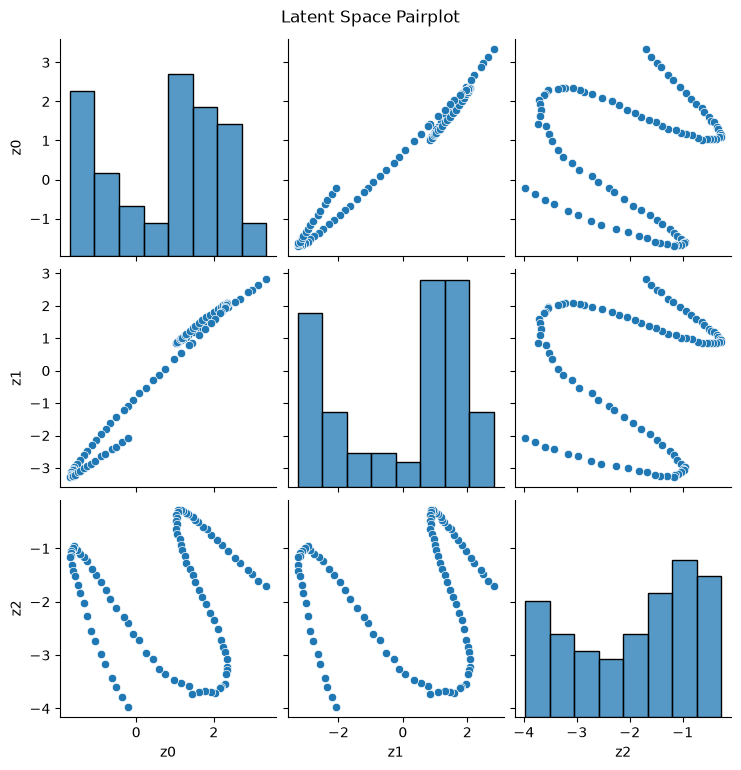

In [41]:
df = pd.DataFrame(z.cpu().detach().numpy(), columns=[f'z{i}' for i in range(z.shape[1])])
sns.pairplot(df)
plt.suptitle('Latent Space Pairplot', y=1.02)
plt.show()


## How might we select the right order in an Autoencoder? Building the case for Least Volume Analysis (LVA)

Our explorations above exposed both the advantages and disadvantages of using non-linear maps to attempt to embed and capture the underlying distribution and topology of the data.

Below we describe the basic principle of "Least Volume" regularization in Autoencoders and demonstrate how it can be useful in providing automated order selection in over-parameterized Autoencoders. It can allow us to capture relevant topological structure, but with minimal dimension.

![](https://arxiv.org/html/2404.17773v1/x1.png)

Image above from: Qiuyi Chen and Mark Fuge, ["Least Volume Analysis"](https://arxiv.org/abs/2404.17773)


In general, the idea behind least volume is that we want to encourage the latent space to take up as little volume as possible, while still being able to reconstruct the data well. This can be achieved by adding a regularization term to the loss function that penalizes the volume of the latent space. A simple way to do this is to penalize the geometric mean of the standard deviation of the latent dimensions, which encourages the latent space to be small in all dimensions. Specifically, we can minimize the product of all elements of the latent code's standard deviation vector $\prod \sigma$, which is equivalent to minimizing the exponential of the mean of the log of the standard deviation vector:

`vol_loss = torch.exp(torch.log(z.std(0) + η).mean())`

We add a small constant `η` to avoid numerical issues when any one of the standard deviations in any dimension approaches zero -- that is when the autoencoder eliminates a dimension, and thus $\prod \sigma$ would have a zero in the product. This loss term can be added to the reconstruction loss, weighted by a hyperparameter `λ`, to form the total loss.

In principle, while this loss can encourage the latent space to reduce its volume, there is one catch: the autoencoder could simply scale up the weights in the encoder and decoder to make the latent space arbitrarily small, while still being able to reconstruct the data well. To prevent this, we have to prevent the decoder from being able to arbitrarily increase its weights, and one easy way to enforce this is through *spectral normalization* on the weights of the decoder, which constrains the Lipschitz constant of the decoder to be at most 1. Because the decoder cannot scale up its weights too much, the encoder cannot easily defeat the volume penalty by isotropically shrinking the weights, and thus the only way to achieve a good volume penalty is to actually reduce dimensions.

Fun Fact: It turns out that in the case of an Autoencoder that only uses Linear layers, and with no activation functions, the least volume penalty is equivalent to PCA. That is, PCA can be seen as a special case of Least Volume Autoencoder. For more details on the mathematical proof, see [Proposition 15](https://arxiv.org/html/2404.17773v2#Thmtheorem15) in the original paper.


Below code implements the spectral normalized decoder:

In [42]:
#| code-fold: false
from torch.nn.utils.parametrizations import spectral_norm

class SNLinearCombo(_Combo):
    def __init__(self, in_features, out_features, activation=nn.LeakyReLU(0.2)):
        super().__init__()
        self.model = nn.Sequential(
            spectral_norm(nn.Linear(in_features, out_features)),
            activation
        )

class SNMLP(MLP):
    def __init__(
        self, in_features: int, out_features: int, layer_width: list,
        combo=SNLinearCombo):
        super().__init__(in_features, out_features, layer_width, combo)

    def _build_model(self, combo):
        model = nn.Sequential()
        idx = -1
        for idx, (in_ftr, out_ftr) in enumerate(self.layer_sizes[:-1]):
            model.add_module(str(idx), combo(in_ftr, out_ftr))
        # Note here is the main difference: the last layer also has spectral normalization
        # This was not the case in the previous MLP definition
        model.add_module(str(idx+1), spectral_norm(nn.Linear(*self.layer_sizes[-1])))
        return model

In [43]:
#| code-fold: false
width = ambient_dim * 16
torch.manual_seed(SEED)
# Note in particular the lack of the bottleneck choice below
# That is, we don't need to actually pick a bottleneck dimension -- LVA tries to determine this automatically, like PCA
encoder = MLP(ambient_dim, ambient_dim, [width] * 4)
# Note also the change in the decoder to have spectral normalization
decoder = SNMLP(ambient_dim, ambient_dim, [width] * 4)

opt = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=1e-3)

In [44]:
#| code-fold: false
η, λ = 0.01, 0.01

for i in range(20000):
    opt.zero_grad()
    z = encoder(X_torch)
    rec_loss = F.mse_loss(decoder(z), X_torch)
    # Note below the least volume loss
    vol_loss = torch.exp(torch.log(z.std(0) + η).mean())
    loss = rec_loss + λ * vol_loss
    loss.backward()
    opt.step()


    if (i+1) % 1000 == 0:
        # Print floats with 5 significant digits and fill epoch with leading spaces if under 4 digits
        print(f'Epoch {i:4}: rec = {rec_loss:.5g}, vol = {vol_loss:.5g}')

Epoch  999: rec = 0.019993, vol = 0.25259
Epoch 1999: rec = 0.012999, vol = 0.14682
Epoch 2999: rec = 0.008948, vol = 0.16614
Epoch 3999: rec = 0.0064253, vol = 0.1986
Epoch 4999: rec = 0.0050592, vol = 0.18064
Epoch 5999: rec = 0.004051, vol = 0.19895
Epoch 6999: rec = 0.0032618, vol = 0.25393
Epoch 7999: rec = 0.0031347, vol = 0.1629
Epoch 8999: rec = 0.0025588, vol = 0.16762
Epoch 9999: rec = 0.0021646, vol = 0.17437
Epoch 10999: rec = 0.0020381, vol = 0.20021
Epoch 11999: rec = 0.0016874, vol = 0.18912
Epoch 12999: rec = 0.001661, vol = 0.17726
Epoch 13999: rec = 0.001643, vol = 0.16763
Epoch 14999: rec = 0.001322, vol = 0.17991
Epoch 15999: rec = 0.001266, vol = 0.1733
Epoch 16999: rec = 0.0011751, vol = 0.17318
Epoch 17999: rec = 0.00116, vol = 0.18069
Epoch 18999: rec = 0.001134, vol = 0.22345
Epoch 19999: rec = 0.0010831, vol = 0.18435


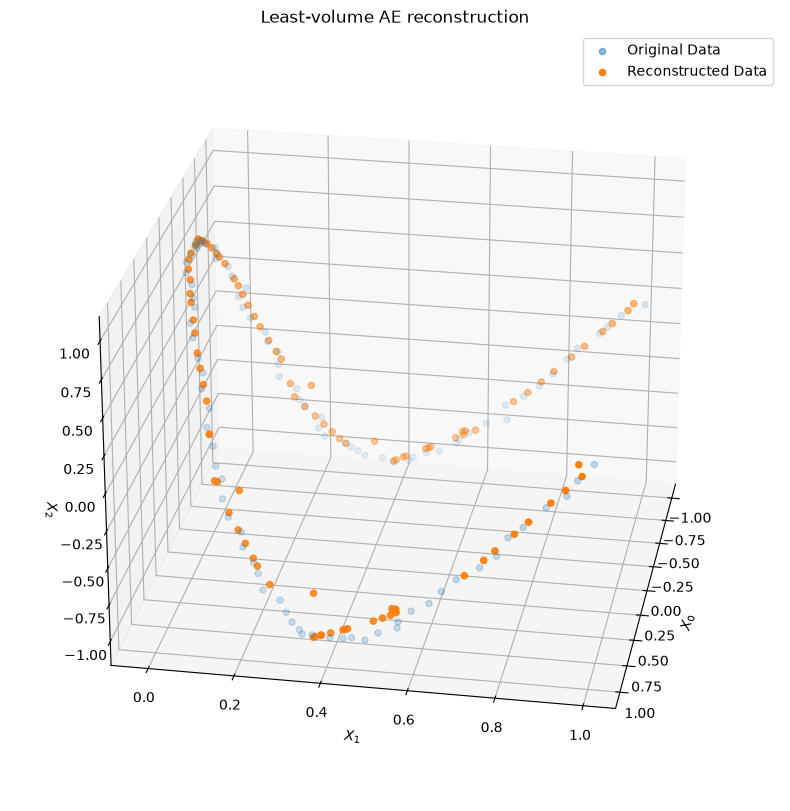

In [45]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(projection='3d')
encoder.eval()
decoder.eval()
with torch.no_grad():
    X_P = decoder(encoder(X_torch)).numpy()
#X_P = decoded.detach().numpy()

ax.scatter(X[:,0], X[:,1], X[:,2],alpha=0.5)
ax.scatter(X_P[:,0], X_P[:,1], X_P[:,2])
ax.set_xlabel('$X_0$')
ax.set_ylabel('$X_1$')
ax.set_zlabel('$X_2$')
ax.elev=25
ax.azim=10
plt.legend(['Original Data','Reconstructed Data'])
plt.title("Least-volume AE reconstruction")
plt.show()

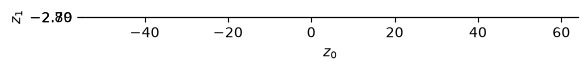

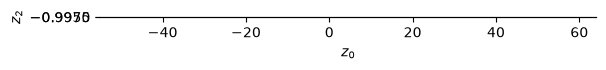

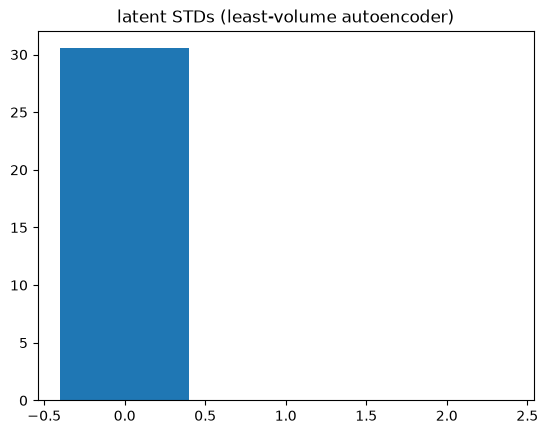

In [46]:
encoder.eval()
decoder.eval()

with torch.no_grad():
    z = encoder(X_torch)
idx = z.std(0).argsort(descending=True)

plt.scatter(z[:, idx[0]].cpu().detach().numpy(), z[:, idx[1]].cpu().detach().numpy(), s=10)
plt.gca().set_aspect('equal')
plt.xlabel('$z_0$')
plt.ylabel('$z_1$')
plt.show()

plt.scatter(z[:, idx[0]].cpu().detach().numpy(), z[:, idx[2]].cpu().detach().numpy(),s=10)
plt.gca().set_aspect('equal')
plt.xlabel('$z_0$')
plt.ylabel('$z_2$')
plt.show()

# Plot the latent STDs by magnitude in the sorted order:
plt.figure()
plt.bar(np.arange(z.std(0).size(-1)), z.std(0)[idx])
plt.title('latent STDs (least-volume autoencoder)')
plt.show()


Compare this bar chart with the one for the plain autoencoder above. The plain autoencoder spread the curve over all three latent dimensions (standard deviations of about 2.0, 1.5 and 1.1), while the least-volume autoencoder keeps far fewer: in this run, one dimension carries almost everything (a standard deviation of about 31) and the other two have collapsed to about 0.005 and 0.001. Do not read too much into the exact count, though. With $\lambda = 0.01$ it is not guaranteed; with other random seeds the same code keeps two active dimensions instead of one.

Plotting the latent code covariances:

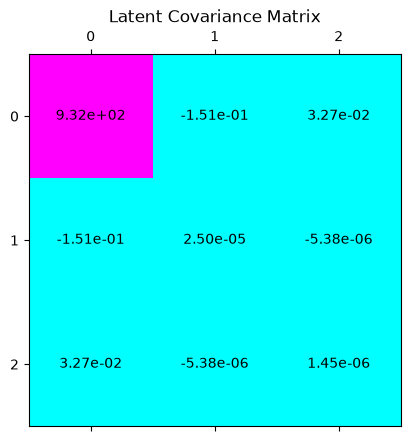

In [47]:
cov = z.T[idx].cov().detach().cpu().numpy()
plt.matshow(cov, cmap='cool')
for (i, j), var in np.ndenumerate(cov):
    plt.gca().text(j, i, '{:.2e}'.format(var), ha='center', va='center')
plt.title('Latent Covariance Matrix')
plt.show()

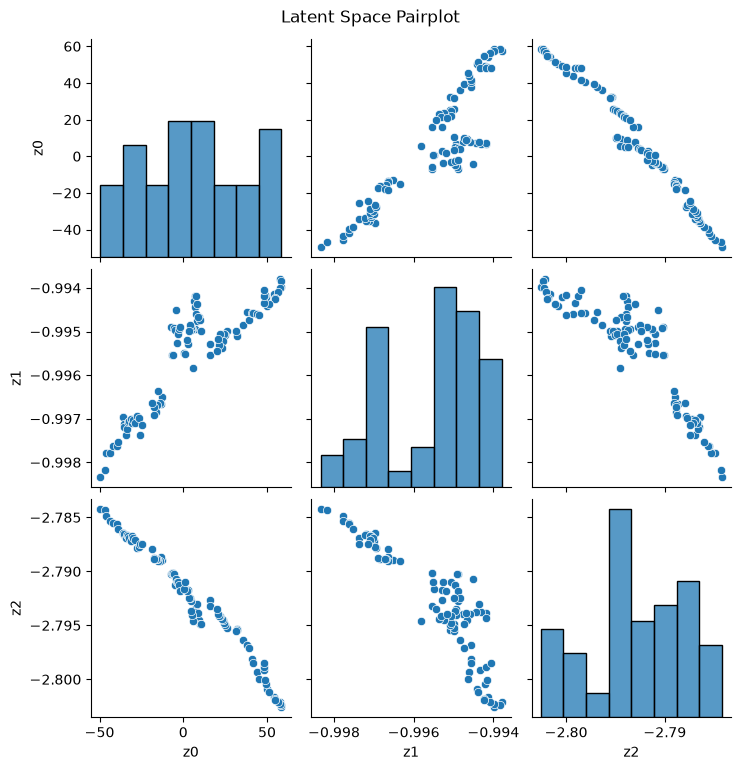

In [48]:
df = pd.DataFrame(z.cpu().detach().numpy(), columns=[f'z{i}' for i in range(z.shape[1])])
sns.pairplot(df)
plt.suptitle('Latent Space Pairplot', y=1.02)
plt.show()

Let's check again the reconstruction errors:

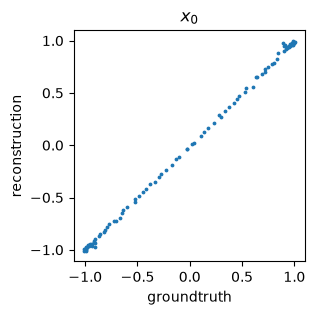

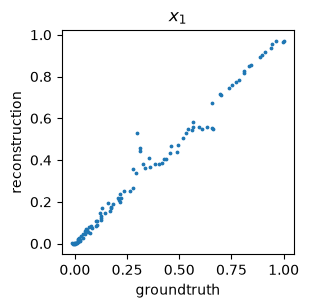

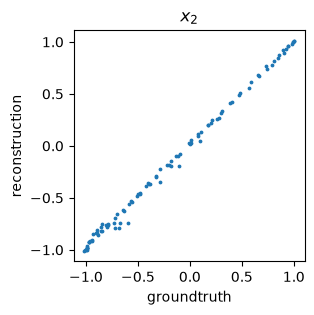

In [49]:
X_ = decoder(z).detach()

for i in range(X_torch.size(-1)):
    plt.figure(figsize=(3,3))
    plt.scatter(X[:, i], X_[:, i], s=3)
    plt.gca().set_aspect('equal')
    plt.xlabel('groundtruth')
    plt.ylabel('reconstruction')
    plt.title('$x_{}$'.format(i))
    plt.show()

### Why does the Decoder Need Spectral Normalization?

For a linear layer, the largest factor by which it can stretch any input is the spectral norm of its weight matrix, $\|W\|_2 = \sigma_{\max}(W)$, its largest singular value. `spectral_norm` divides each weight matrix by a power-iteration estimate of $\sigma_{\max}(W)$, updated on every forward pass in training mode, so $\|W_\ell\|_2 \approx 1$ (slightly above 1 below, because the estimate is a lower bound). Since LeakyReLU's activation function has a bounded Lipschitz constant ($\leq 1$) it never further stretches its input beyond what the weight matrix does, and thus the decoder's Jacobian obeys

$$
\|J_g(z)\|_2 \le \prod_{\ell} \|W_\ell\|_2 \approx 1 .
$$

Without this bound on the decoder, the encoder can shrink every latent dimension by a factor $c$, $z' = z / c$, and the decoder can undo it by $g'(z') = g(c\, z')$. The reconstruction stays the same and the volume penalty drops by (nearly) the factor $c$. The cell below trains the same least-volume autoencoder with a plain decoder for 5000 steps to show this.

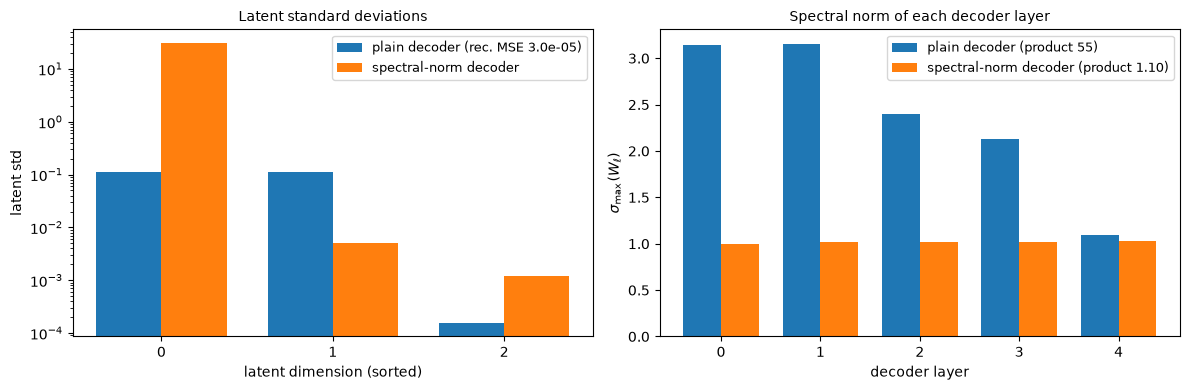

In [50]:
def layer_spectral_norms(net):
    """Largest singular value of each linear layer's (effective) weight matrix."""
    return [torch.linalg.matrix_norm(m.weight.detach(), ord=2).item() for m in net.modules() if isinstance(m, nn.Linear)]


torch.manual_seed(SEED)
encoder_plain = MLP(ambient_dim, ambient_dim, [width] * 4)
decoder_plain = MLP(ambient_dim, ambient_dim, [width] * 4)  # no spectral normalization
opt_plain = torch.optim.Adam(list(encoder_plain.parameters()) + list(decoder_plain.parameters()), lr=1e-3)
for i in range(5000):
    opt_plain.zero_grad()
    z_plain = encoder_plain(X_torch)
    loss = F.mse_loss(decoder_plain(z_plain), X_torch) + λ * torch.exp(torch.log(z_plain.std(0) + η).mean())
    loss.backward()
    opt_plain.step()

with torch.no_grad():
    z_plain = encoder_plain(X_torch)
    rec_plain = F.mse_loss(decoder_plain(z_plain), X_torch).item()
std_plain = z_plain.std(0).sort(descending=True).values.numpy()
decoder.eval()  # measure the spectral-norm decoder without updating its power iteration
with torch.no_grad():
    z_sn = encoder(X_torch)
std_sn = z_sn.std(0).sort(descending=True).values.numpy()
norms_plain, norms_sn = layer_spectral_norms(decoder_plain), layer_spectral_norms(decoder)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bar = 0.38
dims, layers = np.arange(len(std_sn)), np.arange(len(norms_sn))
axes[0].bar(dims - bar / 2, std_plain, bar, label=f"plain decoder (rec. MSE {rec_plain:.1e})")
axes[0].bar(dims + bar / 2, std_sn, bar, label="spectral-norm decoder")
axes[0].set_yscale("log")
axes[0].set_xticks(dims)
axes[0].set_xlabel("latent dimension (sorted)")
axes[0].set_ylabel("latent std")
axes[0].set_title("Latent standard deviations", fontsize=10)
axes[0].legend(fontsize=9)
axes[1].bar(layers - bar / 2, norms_plain, bar, label=f"plain decoder (product {np.prod(norms_plain):.0f})")
axes[1].bar(layers + bar / 2, norms_sn, bar, label=f"spectral-norm decoder (product {np.prod(norms_sn):.2f})")
axes[1].set_xticks(layers)
axes[1].set_xlabel("decoder layer")
axes[1].set_ylabel(r"$\sigma_{\max}(W_\ell)$")
axes[1].set_title("Spectral norm of each decoder layer", fontsize=10)
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

With the plain decoder, the largest latent standard deviation is about 0.1 instead of about 31. The encoder shrinks the whole code, and the decoder's layers grow to undo it: the product of their spectral norms is about 55, and the reconstruction is still excellent. The plain run also drops one dimension, but most of its lower volume comes from shrinking. With spectral normalization, the code cannot shrink for free, so the penalty has to act by removing dimensions, and the surviving dimension stays on the scale of the data.

## Exercises

The exercises reuse the chapter's data, networks and training loops, so run the chapter's cells first. Rough time estimates are in the titles.

::: {.callout-note appearance="simple" icon=false}
### Exercise 1 (~10 min): Count the parameters
Each `nn.Linear(n_in, n_out)` layer holds a weight matrix with `n_out` rows and `n_in` columns and a bias vector with `n_out` entries. Counting them by hand is a quick check that you know what a network definition actually builds. You can check your counts afterwards with `sum(p.numel() for p in model.parameters())`.

- (a) How many trainable parameters does the chapter's first autoencoder, `AutoEncoder(D_orig, num_latent, num_hidden)` with `D_orig = 3`, `num_latent = 3` and `num_hidden = 5`, have? Count layer by layer through the `Encoder` and `Decoder` classes. Why do the `nn.ReLU()` layers add nothing to the count?
- (b) How many trainable parameters does the least-volume encoder, `MLP(ambient_dim, ambient_dim, [width] * 4)` with `ambient_dim = 3` and `width = 48`, have? Its layers are built in a loop by `MLP._build_model`. Which layers hold most of the parameters, and why?
:::

In [51]:
# You can use this code cell for this exercise, if you like.

---

Exercise 2 changes the loss function. Run the cell below. It copies the training targets `y_train` into `y_train_faulty` and replaces two readings with the value 3, as a faulty sensor might. It also defines `make_mlp(seed)`, which builds the chapter's deep network from the list-expansion cell (four hidden layers of 7 ReLU units) with fresh random weights. The default seed is the chapter's `SEED`.

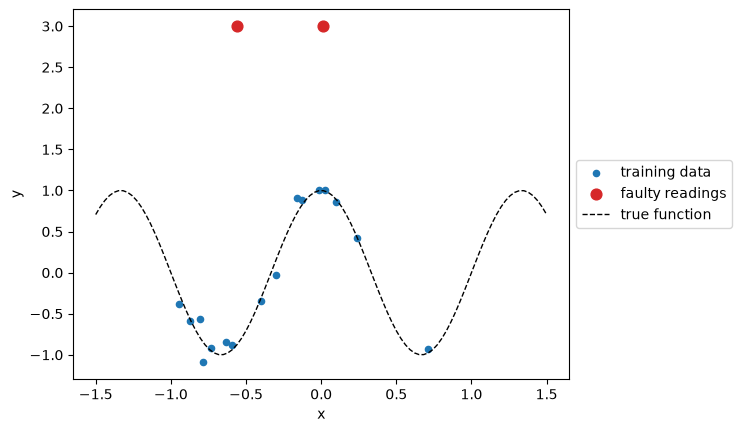

In [52]:
# Two faulty sensor readings: copy the training targets and corrupt two of them
faulty_points = [3, 10]  # the readings at x = 0.010 and x = -0.559
y_train_faulty = y_train.copy()
y_train_faulty[faulty_points] = 3.0


def make_mlp(seed=SEED, activation=nn.ReLU, hidden_size=7, num_hidden_layers=3):
    """The chapter's deep network (1 -> 7 -> 7 -> 7 -> 7 -> 1) with fresh random weights."""
    torch.manual_seed(seed)
    layers = [nn.Linear(1, hidden_size), activation()]
    for _ in range(num_hidden_layers):
        layers.append(nn.Linear(hidden_size, hidden_size))
        layers.append(activation())
    layers.append(nn.Linear(hidden_size, 1))
    return nn.Sequential(*layers)


plt.figure()
plt.scatter(X_train, y_train_faulty, c="tab:blue", s=20, label="training data")
plt.scatter(X_train[faulty_points], y_train_faulty[faulty_points], c="tab:red", s=60, label="faulty readings")
plt.plot(X_plot, true_func(X_plot), "k--", lw=1, label="true function")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 2 (~15 min): Change the loss
The chapter trains every network with the mean squared error, `nn.MSELoss()`. Here you change that choice and see what it does to the fit.

- (a) Copy the chapter's training loop and train two networks from `make_mlp()` on `y_train_faulty`: one with `nn.MSELoss()` and one with the mean absolute error, `nn.L1Loss()`. Plot both fits together with the data. How do the two fits differ near the faulty readings and away from them? Why is the squared loss pulled so much more toward the faulty readings?
- (b) (Optional) Suppose you know that the response is symmetric, $f(x) = f(-x)$. Go back to the clean `y_train` and add the term `torch.mean((model(x_extra) - model(-x_extra))**2)` to the loss, where `x_extra` is a tensor of extra inputs that you choose, for example `torch.linspace(0, 1.5, 31).reshape(-1, 1)`. These inputs need no measured outputs. Compare the fits with and without this term, especially outside $[-1, 1]$ and for $x > 0.25$, where the training data are sparse. Why can a term that uses no measured outputs improve the fit?
:::

In [53]:
# You can use this code cell for this exercise, if you like.

---

Run the cell below to produce the figure for Exercise 3. It trains the chapter's deep network three times, each time with a different activation function, using the chapter's settings (Adam with learning rate 0.05, 5000 epochs, mean squared error). This takes about a minute. The shaded bands mark $|x| > 1$, where there are no training data.

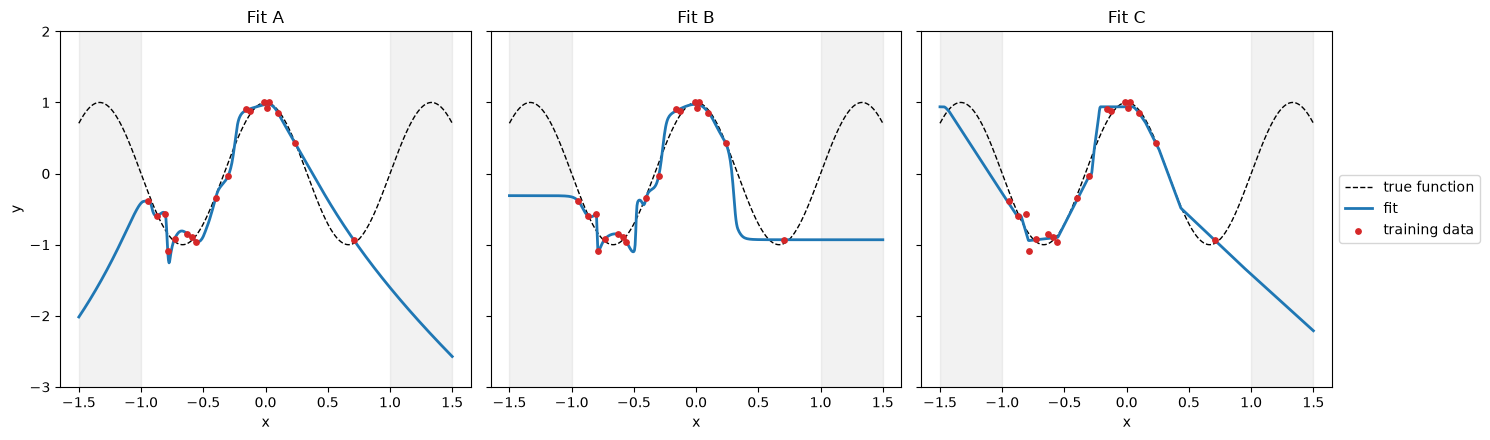

In [54]:
#| echo: false
def fit_with_activation(activation, seed, epochs=5000, learning_rate=0.05):
    """Train the chapter's deep network with the given activation, exactly as in the chapter."""
    net = make_mlp(seed=seed, activation=activation)
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    inputs, targets = torch.from_numpy(X_train), torch.from_numpy(y_train)
    for epoch in range(epochs):
        loss = nn.functional.mse_loss(net(inputs), targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return net


panels = {"A": (nn.ELU, 1), "B": (nn.Tanh, 2), "C": (nn.ReLU, 2)}
x_fine = np.linspace(-1.5, 1.5, 601).reshape(-1, 1).astype(np.float32)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (label, (activation, seed)) in zip(axes, panels.items()):
    net = fit_with_activation(activation, seed)
    with torch.no_grad():
        prediction = net(torch.from_numpy(x_fine)).numpy()
    ax.plot(x_fine, true_func(x_fine), "k--", lw=1, label="true function")
    ax.plot(x_fine, prediction, "tab:blue", lw=2, label="fit")
    ax.scatter(X_train, y_train, c="tab:red", s=15, zorder=3, label="training data")
    ax.axvspan(-1.5, -1, color="gray", alpha=0.1)
    ax.axvspan(1, 1.5, color="gray", alpha=0.1)
    ax.set_title(f"Fit {label}")
    ax.set_xlabel("x")
    ax.set_ylim(-3, 2)
axes[0].set_ylabel("y")
axes[2].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 3 (~10 min): Match the activation
Fits A, B and C above were trained with ReLU, Tanh and ELU activations, in some order.

- (a) Which activation produced which fit, and why? Use the chapter's gallery of activation functions and say what gave each one away.
- (b) Why does the shape of the activation function show up most clearly outside the training data?
- (c) Check one of your answers: set `activation` in the chapter's list-expansion cell to the activation you picked for one of the fits, re-run that cell and the training and plotting cells below it, and compare. Which features of the fit come back, and why might the details differ?
- (d) (Optional) Keep `activation = nn.ReLU` and re-run the list-expansion cell and the training cells with a few other seeds, for example `torch.manual_seed(0)` up to `torch.manual_seed(9)` in place of `torch.manual_seed(SEED)`. For some seeds the fit is a flat line. Why does this happen with ReLU?
:::

In [55]:
# You can use this code cell for this exercise, if you like.

---

Exercise 4 compares the chapter's volume penalty with two simpler definitions of volume. The first cell below sets up the penalties for part (a): the chapter's geometric mean is written for you, and `naive_volume` and `mean_std` are left for you to fill in.

The second cell plots precomputed training runs for parts (b) to (d). Each run trains the chapter's least-volume autoencoder exactly as the chapter does (seed 2, $\lambda = 0.01$, 20000 steps), but with one of the three penalties. The top row shows the sorted latent standard deviations. The middle row shows how hard the penalty pushes on each of them, $|\lambda\, \partial P / \partial \sigma_i|$, the gradient of the weighted penalty $\lambda P$ with respect to each standard deviation $\sigma_i$. The bottom row shows the reconstruction error, as a running median over 500 steps, with a run without any penalty in gray.

In [56]:
def geometric_volume(std, eta=0.01):
    """The chapter's least-volume penalty: the geometric mean of the (shifted) standard deviations."""
    return torch.exp(torch.log(std + eta).mean())


def naive_volume(std):
    """The product of the standard deviations (write this one)."""
    pass


def mean_std(std):
    """The arithmetic mean of the standard deviations (write this one)."""
    pass


def compare_penalties(penalties, std_values=((2.0, 1.5, 0.01), (2.0, 1.5, 0.0))):
    """Print each penalty's value and its gradient with respect to each standard deviation."""
    for values in std_values:
        print(f"std = {values}")
        for penalty in penalties:
            std = torch.tensor(values, requires_grad=True)
            value = penalty(std)
            value.backward()
            print(f"  {penalty.__name__:>16}: value {value.item():.4f}, gradient {np.round(std.grad.numpy(), 4)}")


# Add naive_volume and mean_std to this list once you have written them
compare_penalties([geometric_volume])

std = (2.0, 1.5, 0.01)
  geometric_volume: value 0.3930, gradient [0.0652 0.0868 6.5501]
std = (2.0, 1.5, 0.0)
  geometric_volume: value 0.3119, gradient [ 0.0517  0.0689 10.3977]


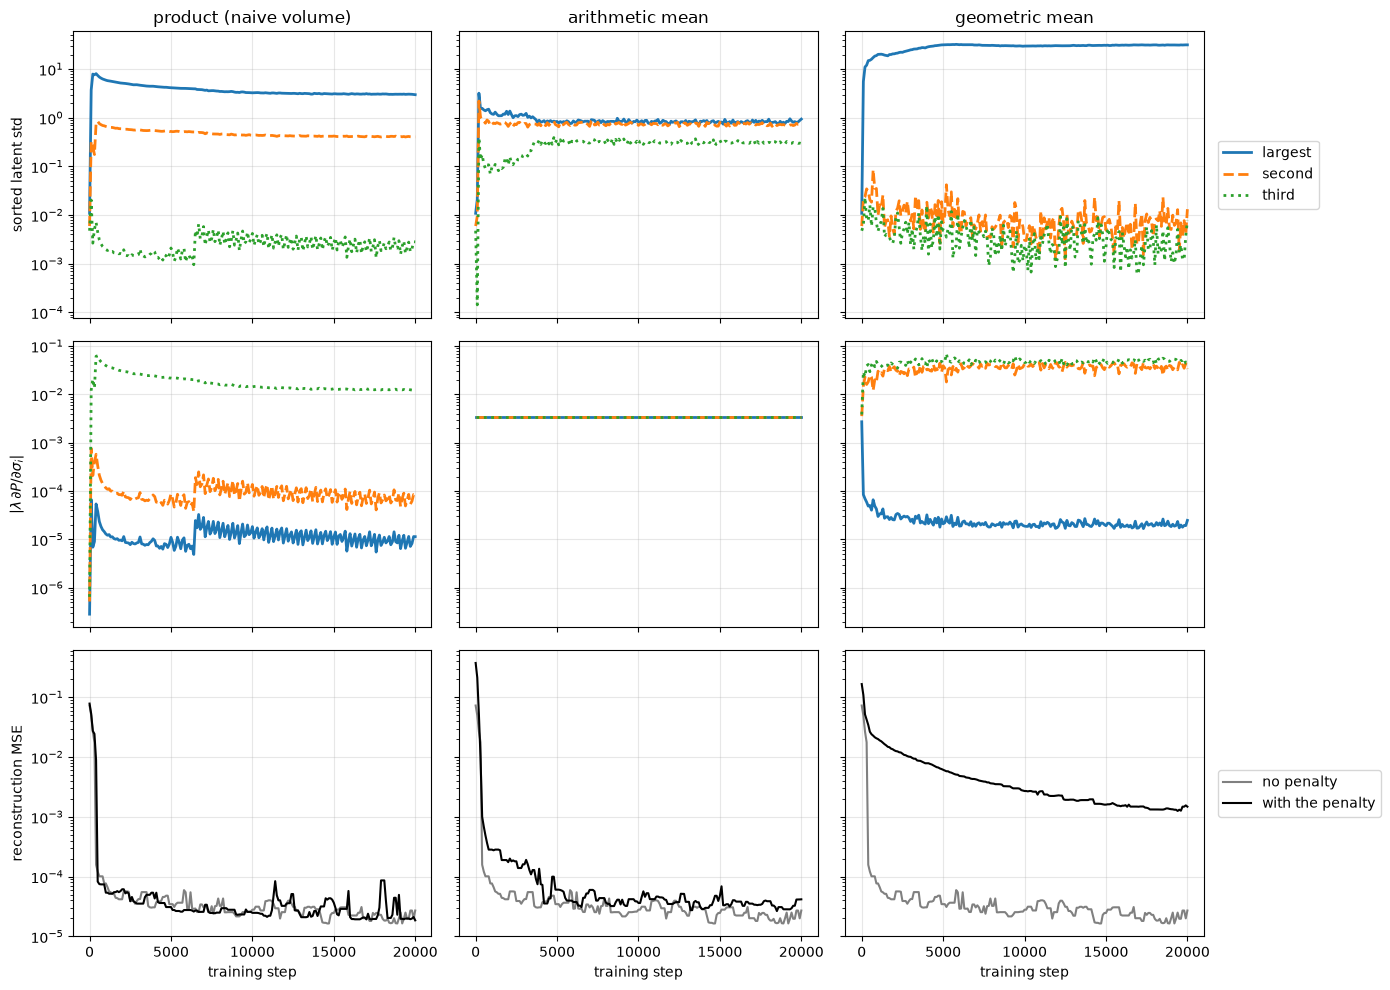

In [57]:
#| echo: false
# Precomputed runs of the chapter's least-volume autoencoder (seed 2, lambda = 0.01, 20000 steps),
# one per penalty. Logged every 100 steps.
PENALTY_CSV = "../data/review_neural_networks_lv_penalties.csv"
# If you don't have the data folder locally (for example on Google Colab), load the GitHub copy instead:
# PENALTY_CSV = "https://raw.githubusercontent.com/IDEALLab/ML4ME_Textbook/main/data/review_neural_networks_lv_penalties.csv"
curves = pd.read_csv(PENALTY_CSV)
penalty_titles = {"product": "product (naive volume)", "arithmetic": "arithmetic mean", "geometric": "geometric mean"}
dim_colors = ["tab:blue", "tab:orange", "tab:green"]
dim_labels = ["largest", "second", "third"]
dim_styles = ["-", "--", ":"]  # different line styles, so that lines lying on top of each other stay visible
baseline = curves[curves["penalty"] == "none"]


def running_median(values):
    """Running median over 5 logged values (500 training steps), to smooth the step-to-step noise."""
    return values.rolling(5, center=True, min_periods=1).median()


fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey="row")
for col, (penalty, title) in enumerate(penalty_titles.items()):
    run = curves[curves["penalty"] == penalty]
    for d in range(3):
        axes[0, col].plot(run["step"], run[f"std_{d + 1}"], color=dim_colors[d], ls=dim_styles[d], lw=2, label=dim_labels[d])
        axes[1, col].plot(run["step"], run[f"grad_{d + 1}"].abs(), color=dim_colors[d], ls=dim_styles[d], lw=2,
                          label=dim_labels[d])
    axes[2, col].plot(baseline["step"], running_median(baseline["rec_mse"]), color="gray", label="no penalty")
    axes[2, col].plot(run["step"], running_median(run["rec_mse"]), color="k", label="with the penalty")
    axes[0, col].set_title(title)
    for ax in axes[:, col]:
        ax.set_yscale("log")
        ax.grid(True, alpha=0.3)
    axes[2, col].set_xlabel("training step")
axes[0, 0].set_ylabel("sorted latent std")
axes[1, 0].set_ylabel(r"$|\lambda\, \partial P / \partial \sigma_i|$")
axes[2, 0].set_ylabel("reconstruction MSE")
axes[0, 2].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
axes[2, 2].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 4 (~15 min): Three ways to penalize volume
The chapter penalizes the geometric mean of the latent standard deviations, $\left(\prod_{i=1}^{d} (\sigma_i + \eta)\right)^{1/d}$, computed as `torch.exp(torch.log(z.std(0) + η).mean())`. Two simpler choices come to mind: the volume itself, $\prod_{i=1}^{d} \sigma_i$, and the arithmetic mean, $\frac{1}{d}\sum_{i=1}^{d} \sigma_i$.

- (a) Write `naive_volume(std)` and `mean_std(std)` in the first cell above and add them to the `compare_penalties` call. For $\sigma = (2.0, 1.5, 0.01)$ and $\sigma = (2.0, 1.5, 0)$ with $\eta = 0.01$, which penalty pushes hardest on which dimension? Why does the product stop pushing on the first two dimensions once the third is zero?
- (b) In the figure, how many latent dimensions does each penalty keep? Use your numbers from (a) to explain why the product stops after it has removed one dimension.
- (c) At the start of training, all three standard deviations are about 0.01. Why does the product push several thousand times less hard than the other two penalties there?
- (d) The geometric mean finds the one-dimensional code, but its reconstruction error is the highest of the three. Why? When might you prefer the product?
:::

---

::: {.callout-note appearance="simple" icon=false}
### Exercise 5 (~10 min): Count the linear pieces
A network with one hidden layer of $h$ ReLU units computes $f(x) = b + \sum_{j=1}^{h} v_j \max(0,\, w_j x + c_j)$. The cell below fits such networks to the chapter's training data for the widths in `hidden_units` (Adam with learning rate 0.02, 2500 epochs, the same random seed for every width), and plots the fits over $[-1.5, 1.5]$.

- (a) Before you run anything: what is the largest number of linear pieces that a network with $h$ units can produce? Why?
- (b) Run the cell as it is, with `hidden_units = [2]`. How many linear pieces does the fit have? Why can it not follow the W shape of the data?
- (c) Change the list to `[2, 4, 6, 8, 16]` and re-run the cell (about 20 seconds). How many units does the network need before it follows the W? The W needs only four linear pieces, so why does the network need more units than that? Exercise 3(d) may help.
:::

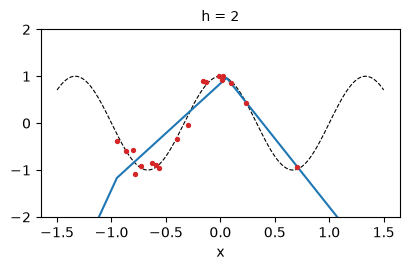

In [58]:
def fit_relu_layer(h, seed, epochs=2500, learning_rate=0.02):
    """Fit a network with one hidden layer of h ReLU units to the chapter's training data."""
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, h), nn.ReLU(), nn.Linear(h, 1))
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    inputs, targets = torch.from_numpy(X_train), torch.from_numpy(y_train)
    for epoch in range(epochs):
        loss = nn.functional.mse_loss(net(inputs), targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return net

    
def plot_relu_fits(hidden_units, seed=121):
    """One panel per width h."""
    x_fine = np.linspace(-1.5, 1.5, 601).reshape(-1, 1).astype(np.float32)
    fig, axes = plt.subplots(1, len(hidden_units), figsize=(3.2 * len(hidden_units) + 1, 2.8),
                             sharex=True, sharey=True, squeeze=False)
    for ax, h in zip(axes[0], hidden_units):
        net = fit_relu_layer(h, seed)
        with torch.no_grad():
            prediction = net(torch.from_numpy(x_fine)).numpy()
        ax.plot(x_fine, true_func(x_fine), "k--", lw=0.8)
        ax.plot(x_fine, prediction, "tab:blue", lw=1.5)
        ax.scatter(X_train, y_train, c="tab:red", s=8, zorder=3)
        ax.set_ylim(-2, 2)
        ax.set_title(f"h = {h}", fontsize=10)
        ax.set_xlabel("x")
    plt.tight_layout()
    plt.show()


# For part (c), change this to [2, 4, 6, 8, 16]
hidden_units = [2]
plot_relu_fits(hidden_units)